# **ALL INSURANCE - CROSS SELL**

<div style="text-align: center; background-color: white; padding-top: 20px;">
    <img src="../images/all-insurance-whitebg.png" alt="All Insurance" width="400"/>
</div>
<br>

O departamento de marketing da All Insurance enfrenta o desafio de identificar, dentro da sua ampla base de clientes de seguros de saúde, aqueles que possuem maior probabilidade de contratar também um seguro automotivo. Essa iniciativa é estratégica, pois a empresa, já consolidada como uma das líderes no segmento de saúde, busca expandir sua atuação para o ramo de seguros de automóveis, aproveitando a confiança e o relacionamento já estabelecido com seus clientes.

Para viabilizar esse objetivo, é necessário desenvolver um modelo de machine learning capaz de prever a propensão de cada cliente em adquirir um seguro automotivo, a partir de informações demográficas e do histórico de apólices. O time de vendas tem capacidade para realizar **20.000 ligações** durante a campanha e, por isso, o modelo deve ordenar a base de novos clientes, colocando no topo da lista aqueles com maior interesse.

# 0.0. Imports

In [1]:
import os
import sys
import json
import time
import pickle
import random
import warnings
import requests
import subprocess

import pandas                  as pd
import numpy                   as np
import seaborn                 as sns
import lightgbm                as lgb
import xgboost                 as xgb
import matplotlib.pyplot       as plt
import matplotlib.image        as mpimg
import matplotlib.ticker       as mtick
import matplotlib.colors       as mcolors
import matplotlib.font_manager as fm

from scipy                import stats           as ss
from sklearn              import preprocessing   as pp
from sklearn              import model_selection as ms
from sklearn              import ensemble        as en
from sklearn              import linear_model    as lm
from sklearn              import neighbors       as nh
from sklearn              import metrics         as mt
from sklearn              import inspection      as it

from sklearn.base         import clone
from sqlalchemy           import create_engine, URL
from dotenv               import load_dotenv
from tabulate             import tabulate
from IPython.display      import display, HTML

warnings.filterwarnings( 'ignore' )

## 0.1. Funções Auxiliares

In [2]:
# paleta de cores do projeto
COLOR_MAIN = '#012d59' # azul da All Insurance
COLOR_GRAY = '#b8c2cc' # cinza para comparação
COLOR_TEXT = '#494b45' # textos
COLOR_AXIS = '#c3c2b7' # eixos
COLOR_GRID = '#e1e0d9' # linhas de grade

def jupyter_settings():
    %matplotlib inline

    display( HTML( '<style>.container { width:100% !important; }</style>' ) )
    pd.options.display.max_columns = None
    pd.options.display.max_rows = 100
    pd.set_option( 'display.expand_frame_repr', False )

    # fonte Roboto
    fm.fontManager.addfont( '../fonts/Roboto-Regular.ttf' )

    sns.set_theme( style='white', font='Roboto' )
    plt.rcParams['figure.figsize'] = [14, 5]
    plt.rcParams['font.size'] = 12
    plt.rcParams['axes.edgecolor'] = COLOR_AXIS
    plt.rcParams['axes.labelcolor'] = COLOR_TEXT
    plt.rcParams['xtick.color'] = COLOR_TEXT
    plt.rcParams['ytick.color'] = COLOR_TEXT
    plt.rcParams['text.color'] = COLOR_TEXT

In [3]:
def fmt_perc( x, decimals=1 ):
    return f'{x * 100:.{decimals}f}%'.replace( '.', ',' )

def fmt_int( x ):
    return f'{x:,.0f}'.replace( ',', '.' )

def fmt_dec( x, decimals=1 ):
    # o arredondamento evita valores como "-0,00"
    return f'{round( x, decimals ) + 0.0:.{decimals}f}'.replace( '.', ',' )

In [4]:
def set_chart( ax, title, xlabel='', ylabel='' ):
    ax.set_title( title, fontsize=15, color=COLOR_TEXT, loc='left', pad=14 )
    ax.set_xlabel( xlabel, fontsize=12, color=COLOR_TEXT )
    ax.set_ylabel( ylabel, fontsize=12, color=COLOR_TEXT )
    ax.tick_params( axis='both', labelsize=11, colors=COLOR_TEXT, length=0 )
    ax.grid( axis='y', color=COLOR_GRID, linewidth=0.8 )
    ax.set_axisbelow( True )
    sns.despine( ax=ax, left=True )

def add_logo( fig ):
    logo = mpimg.imread( '../images/logo-small.png' )
    ax_logo = fig.add_axes( [0.86, 0.95, 0.12, 0.07], anchor='NE', zorder=10 )
    ax_logo.imshow( logo, alpha=0.7 )
    ax_logo.axis( 'off' )

def save_fig( fig, name ):
    fig.savefig( f'../images/{name}.png', dpi=120, bbox_inches='tight', facecolor='white' )

In [5]:
def plot_share( ax, data, col, title, xlabel, order=None, labels=None ):
    aux = data[col].value_counts( normalize=True )
    if order is not None:
        aux = aux.loc[order]

    xticks = labels if labels is not None else [str( x ) for x in aux.index]

    bars = ax.bar( xticks, aux.values, width=0.45, color=COLOR_MAIN )
    ax.bar_label( bars, labels=[fmt_perc( v ) for v in aux.values], padding=4, color=COLOR_TEXT, fontsize=11 )

    ax.yaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
    ax.set_ylim( 0, aux.max() * 1.2 )
    set_chart( ax, title, xlabel, 'Clientes (%)' )

def plot_rate( ax, data, col, title, xlabel, order=None, labels=None, highlight=None, rate_mean=None ):
    aux = data[[col, 'response']].groupby( col, observed=True ).agg( rate=( 'response', 'mean' ), n=( 'response', 'size' ) )
    if order is not None:
        aux = aux.loc[order]

    xticks = labels if labels is not None else [str( x ) for x in aux.index]
    colors = [COLOR_MAIN if ( highlight is None or x in highlight ) else COLOR_GRAY for x in aux.index]

    bars = ax.bar( xticks, aux['rate'], width=0.45, color=colors )
    ax.bar_label( bars, labels=[fmt_perc( v ) for v in aux['rate']], padding=4, color=COLOR_TEXT, fontsize=11,
                  bbox={ 'facecolor': 'white', 'edgecolor': 'none', 'pad': 1 } )

    # taxa média de interesse da base
    rate_mean = data['response'].mean() if rate_mean is None else rate_mean
    ax.axhline( rate_mean, color=COLOR_TEXT, linewidth=1 )
    ax.annotate( f'média geral\n{fmt_perc( rate_mean )}', xy=( 1, rate_mean ), xycoords=( 'axes fraction', 'data' ),
                 xytext=( 6, 0 ), textcoords='offset points', ha='left', va='center', fontsize=10, color=COLOR_TEXT )

    ax.yaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
    ax.set_ylim( 0, max( aux['rate'].max(), rate_mean ) * 1.2 )
    set_chart( ax, title, xlabel, 'Taxa de interesse' )

    return aux

def plot_distribution( ax, data, col, title, xlabel, clip=None ):
    aux = data[[col, 'response']].copy()
    if clip is not None:
        aux = aux[aux[col] <= clip]

    sns.kdeplot( data=aux[aux['response'] == 0], x=col, ax=ax, color=COLOR_GRAY, fill=True, alpha=0.3, linewidth=2, cut=0, label='Não interessado' )
    sns.kdeplot( data=aux[aux['response'] == 1], x=col, ax=ax, color=COLOR_MAIN, fill=True, alpha=0.15, linewidth=2, cut=0, label='Interessado' )

    ax.legend( frameon=False, fontsize=11 )
    ax.set_yticks( [] )
    set_chart( ax, title, xlabel, 'Densidade' )

In [6]:
def cramer_v( x, y ):
    cm = pd.crosstab( x, y ).values
    n = cm.sum()
    r, k = cm.shape

    chi2 = ss.chi2_contingency( cm )[0]
    chi2corr = max( 0, chi2 - ( k - 1 ) * ( r - 1 ) / ( n - 1 ) )

    kcorr = k - ( k - 1 )**2 / ( n - 1 )
    rcorr = r - ( r - 1 )**2 / ( n - 1 )

    return np.sqrt( ( chi2corr / n ) / ( min( kcorr - 1, rcorr - 1 ) ) )

In [7]:
def precision_at_k( y_true, y_score, k ):
    # ordena os clientes pelo score e seleciona os k primeiros
    idx = np.argsort( -np.asarray( y_score ), kind='stable' )[:k]

    return np.asarray( y_true )[idx].sum() / k

def recall_at_k( y_true, y_score, k ):
    # ordena os clientes pelo score e seleciona os k primeiros
    idx = np.argsort( -np.asarray( y_score ), kind='stable' )[:k]

    return np.asarray( y_true )[idx].sum() / np.asarray( y_true ).sum()

def ml_metrics( model_name, y_true, y_score, perc ):
    # k proporcional ao tamanho da base avaliada
    k = int( len( y_true ) * perc )

    return pd.DataFrame( {
        'Model Name': model_name,
        'Precision@K': precision_at_k( y_true, y_score, k ),
        'Recall@K': recall_at_k( y_true, y_score, k ),
        'ROC AUC': mt.roc_auc_score( y_true, y_score )}, index=[0] )

In [8]:
def cross_validation( model_name, model, x_training, y_training, kfold, perc, verbose=False ):

    precision_list = list()
    recall_list = list()
    auc_list = list()

    # predições de cada cliente no fold em que ele foi validação
    yhat_oof = np.zeros( len( y_training ) )

    skf = ms.StratifiedKFold( n_splits=kfold, shuffle=True, random_state=42 )

    for k, ( train_idx, val_idx ) in enumerate( skf.split( x_training, y_training ), start=1 ):

        # treino
        xtraining = x_training.iloc[train_idx]
        ytraining = y_training.iloc[train_idx]

        # validação
        xvalidation = x_training.iloc[val_idx]
        yvalidation = y_training.iloc[val_idx]

        # modelo
        m = clone( model ).fit( xtraining, ytraining )

        # predição
        yhat = m.predict_proba( xvalidation )[:, 1]
        yhat_oof[val_idx] = yhat

        # performance
        result = ml_metrics( model_name, yvalidation, yhat, perc )

        if verbose:
            print( f'KFold Number {k}' )
            print( result, end='\n\n' )

        # performance de cada fold
        precision_list.append( result.loc[0, 'Precision@K'] )
        recall_list.append( result.loc[0, 'Recall@K'] )
        auc_list.append( result.loc[0, 'ROC AUC'] )

    return pd.DataFrame( {
        'Model Name': model_name,
        'Precision@K CV': f'{np.mean( precision_list ):.4f} ± {np.std( precision_list ):.4f}',
        'Recall@K CV': f'{np.mean( recall_list ):.4f} ± {np.std( recall_list ):.4f}',
        'ROC AUC CV': f'{np.mean( auc_list ):.4f} ± {np.std( auc_list ):.4f}'}, index=[0] ), yhat_oof

In [9]:
def cumulative_gain( y_true, y_score ):
    aux = pd.DataFrame( { 'response': np.asarray( y_true ), 'score': np.asarray( y_score ) } )
    aux = aux.sort_values( 'score', ascending=False, kind='stable' ).reset_index( drop=True )

    # proporção da base contatada x proporção dos interessados alcançados
    aux['perc_base'] = ( aux.index + 1 ) / len( aux )
    aux['perc_interessados'] = aux['response'].cumsum() / aux['response'].sum()
    aux['lift'] = aux['perc_interessados'] / aux['perc_base']

    return aux

In [10]:
jupyter_settings()

## 0.2. Carregando os Dados

Os dados estão armazenados no banco de dados PostgreSQL da All Insurance, distribuídos em três tabelas: `clientes`, `apolices` e `veiculos`, relacionadas pela chave `id_cliente`. As credenciais de acesso ficam no arquivo `.env`, que não é versionado (o modelo está no arquivo `.env.example`).

In [11]:
# credenciais do banco de dados, lidas do arquivo .env
load_dotenv( '../.env' )

url = URL.create(
    drivername='postgresql+psycopg',
    username=os.getenv( 'DB_USER' ),
    password=os.getenv( 'DB_PASSWORD' ),
    host=os.getenv( 'DB_HOST' ),
    port=int( os.getenv( 'DB_PORT', 5432 ) ),
    database=os.getenv( 'DB_NAME' ) )

engine = create_engine( url )
schema = os.getenv( 'DB_SCHEMA', 'public' )

In [12]:
# join das três tabelas no banco de dados
query = f"""
    SELECT c.id_cliente, c.gender, c.age, c.region_code, c.driving_license,
           a.id_apolice, a.previously_insured, a.annual_premium, a.policy_sales_channel, a.vintage, a.response,
           v.id_veiculo, v.vehicle_age, v.vehicle_damage
    FROM {schema}.clientes c
    INNER JOIN {schema}.apolices a ON a.id_cliente = c.id_cliente
    INNER JOIN {schema}.veiculos v ON v.id_cliente = c.id_cliente
    ORDER BY c.id_cliente
"""

df_full = pd.read_sql( query, engine )
engine.dispose()

df_full.head()

,id_cliente,gender,age,region_code,driving_license,id_apolice,previously_insured,annual_premium,policy_sales_channel,vintage,response,id_veiculo,vehicle_age,vehicle_damage
0,1,Male,44,28.0,1,1,0,40454.0,26.0,217,1.0,1,> 2 Years,Yes
1,2,Male,76,3.0,1,2,0,33536.0,26.0,183,0.0,2,1-2 Year,No
2,3,Male,47,28.0,1,3,0,38294.0,26.0,27,1.0,3,> 2 Years,Yes
3,4,Male,21,11.0,1,4,1,28619.0,152.0,203,0.0,4,< 1 Year,No
4,5,Female,29,41.0,1,5,1,27496.0,152.0,39,0.0,5,< 1 Year,No


In [13]:
# clientes que responderam à pesquisa de interesse no seguro automotivo
df_raw = df_full[df_full['response'].notna()].copy()

# novos clientes: ainda não foram contatados e serão ranqueados para a campanha
df_novos = df_full[df_full['response'].isna()].drop( 'response', axis=1 ).copy()

print( f'Clientes que responderam à pesquisa: {fmt_int( df_raw.shape[0] )}' )
print( f'Novos clientes: {fmt_int( df_novos.shape[0] )}' )

Clientes que responderam à pesquisa: 381.109
Novos clientes: 127.037


In [14]:
# capacidade do time de vendas durante a campanha
CALLS = 20000

# proporção da base de novos clientes que o time de vendas consegue contatar
PERC_CALLS = CALLS / df_novos.shape[0]

print( f'Com {fmt_int( CALLS )} ligações, o time de vendas contata {fmt_perc( PERC_CALLS, 2 )} da base de novos clientes' )

Com 20.000 ligações, o time de vendas contata 15,74% da base de novos clientes


In [15]:
del df_full

# 1.0. DESCRIÇÃO DOS DADOS

In [16]:
df1 = df_raw.copy()

## 1.1. Dimensão dos Dados

In [17]:
print( f'Número de Linhas: {fmt_int( df1.shape[0] )}' )
print( f'Número de Colunas: {df1.shape[1]}' )

Número de Linhas: 381.109
Número de Colunas: 14


## 1.2. Tipos de Dados

In [18]:
df1.dtypes

id_cliente                int64
gender                      str
age                       int64
region_code             float64
driving_license           int64
id_apolice                int64
previously_insured        int64
annual_premium          float64
policy_sales_channel    float64
vintage                   int64
response                float64
id_veiculo                int64
vehicle_age                 str
vehicle_damage              str
dtype: object

## 1.3. Verificação de Dados Faltantes

In [19]:
df1.isna().sum()

id_cliente              0
gender                  0
age                     0
region_code             0
driving_license         0
id_apolice              0
previously_insured      0
annual_premium          0
policy_sales_channel    0
vintage                 0
response                0
id_veiculo              0
vehicle_age             0
vehicle_damage          0
dtype: int64

## 1.4. Alteração de Tipos

In [20]:
# region_code e policy_sales_channel são códigos e não possuem casas decimais
df1['region_code'] = df1['region_code'].astype( 'int64' )
df1['policy_sales_channel'] = df1['policy_sales_channel'].astype( 'int64' )

# response
df1['response'] = df1['response'].astype( 'int64' )

df1.dtypes

id_cliente                int64
gender                      str
age                       int64
region_code               int64
driving_license           int64
id_apolice                int64
previously_insured        int64
annual_premium          float64
policy_sales_channel      int64
vintage                   int64
response                  int64
id_veiculo                int64
vehicle_age                 str
vehicle_damage              str
dtype: object

## 1.5. Estatística Descritiva

In [21]:
# region_code e policy_sales_channel são numéricas, mas representam categorias
num_attributes = df1[['age', 'annual_premium', 'vintage']]
cat_attributes = df1[['gender', 'region_code', 'driving_license', 'previously_insured', 'policy_sales_channel', 'vehicle_age', 'vehicle_damage']]

### 1.5.1. Atributos Numéricos

In [22]:
# Tendência Central - média e mediana
ct1 = pd.DataFrame( num_attributes.apply( np.mean ) ).T
ct2 = pd.DataFrame( num_attributes.apply( np.median ) ).T

# Dispersão - desvio padrão, mínimo, máximo, amplitude, assimetria e curtose
d1 = pd.DataFrame( num_attributes.apply( np.std ) ).T
d2 = pd.DataFrame( num_attributes.apply( np.min ) ).T
d3 = pd.DataFrame( num_attributes.apply( np.max ) ).T
d4 = pd.DataFrame( num_attributes.apply( lambda x: x.max() - x.min() ) ).T
d5 = pd.DataFrame( num_attributes.apply( lambda x: x.skew() ) ).T
d6 = pd.DataFrame( num_attributes.apply( lambda x: x.kurtosis() ) ).T

# concatena
m = pd.concat( [d2, d3, d4, ct1, ct2, d1, d5, d6] ).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,age,20.0,85.0,65.0,38.822584,36.0,15.511591,0.672539,-0.565655
1,annual_premium,2630.0,540165.0,537535.0,30564.389581,31669.0,17213.132474,1.766087,34.004569
2,vintage,10.0,299.0,289.0,154.347397,154.0,83.671194,0.003030,-1.200688


In [23]:
# proporção de clientes que pagam o menor prêmio anual da base
min_premium = df1['annual_premium'].min()

print( f"Clientes com prêmio anual de {fmt_int( min_premium )}: {fmt_perc( ( df1['annual_premium'] == min_premium ).mean() )}" )

Clientes com prêmio anual de 2.630: 17,0%


**OBS.: A variável `annual_premium` tem assimetria e curtose altas, ou seja, muitos outliers à direita. Além disso, 17% dos clientes pagam exatamente o menor valor da base (2.630), o que sugere um prêmio mínimo cobrado pela All Insurance.**

### 1.5.2. Atributos Categóricos

In [24]:
cat_attributes.apply( lambda x: x.unique().shape[0] )

gender                    2
region_code              53
driving_license           2
previously_insured        2
policy_sales_channel    155
vehicle_age               3
vehicle_damage            2
dtype: int64

In [25]:
for col in ['gender', 'vehicle_age', 'vehicle_damage', 'driving_license', 'previously_insured']:
    print( df1[col].value_counts( normalize=True ).round( 4 ), end='\n\n' )

gender
Male      0.5408
Female    0.4592
Name: proportion, dtype: float64

vehicle_age
1-2 Year     0.5256
< 1 Year     0.4324
> 2 Years    0.0420
Name: proportion, dtype: float64

vehicle_damage
Yes    0.5049
No     0.4951
Name: proportion, dtype: float64

driving_license
1    0.9979
0    0.0021
Name: proportion, dtype: float64

previously_insured
0    0.5418
1    0.4582
Name: proportion, dtype: float64



# 2.0. FEATURE ENGINEERING

In [26]:
df2 = df1.copy()

del df_raw

## 2.1. Mapa Mental de Hipóteses

![Mapa Mental de Hipóteses](../images/mindmap_hipoteses.png)

## 2.2. Criação de Hipóteses

### 2.2.1. Hipóteses Cliente

**1.** Clientes mais velhos deveriam ter mais interesse em adquirir um seguro automotivo.

**2.** Clientes do sexo masculino deveriam ter mais interesse em adquirir um seguro automotivo.

**3.** Clientes com carteira de motorista deveriam ter mais interesse em adquirir um seguro automotivo.

**4.** Clientes de regiões com mais clientes deveriam ter mais interesse em adquirir um seguro automotivo.

### 2.2.2. Hipóteses Veículo

**1.** Clientes com veículos mais novos deveriam ter mais interesse em adquirir um seguro automotivo.

**2.** Clientes que já tiveram o veículo danificado deveriam ter mais interesse em adquirir um seguro automotivo.

### 2.2.3. Hipóteses Apólice

**1.** Clientes que já possuem seguro automotivo deveriam ter menos interesse em adquirir um seguro automotivo.

**2.** Clientes que pagam um prêmio anual maior no seguro saúde deveriam ter mais interesse em adquirir um seguro automotivo.

**3.** Clientes com mais tempo de relacionamento com a All Insurance deveriam ter mais interesse em adquirir um seguro automotivo.

**4.** Clientes captados pelos canais de venda mais utilizados deveriam ter mais interesse em adquirir um seguro automotivo.

## 2.3. Lista Final de Hipóteses

**1.** Clientes mais velhos deveriam ter mais interesse em adquirir um seguro automotivo.

**2.** Clientes do sexo masculino deveriam ter mais interesse em adquirir um seguro automotivo.

**3.** Clientes com carteira de motorista deveriam ter mais interesse em adquirir um seguro automotivo.

**4.** Clientes de regiões com mais clientes deveriam ter mais interesse em adquirir um seguro automotivo.

**5.** Clientes com veículos mais novos deveriam ter mais interesse em adquirir um seguro automotivo.

**6.** Clientes que já tiveram o veículo danificado deveriam ter mais interesse em adquirir um seguro automotivo.

**7.** Clientes que já possuem seguro automotivo deveriam ter menos interesse em adquirir um seguro automotivo.

**8.** Clientes que pagam um prêmio anual maior no seguro saúde deveriam ter mais interesse em adquirir um seguro automotivo.

**9.** Clientes com mais tempo de relacionamento com a All Insurance deveriam ter mais interesse em adquirir um seguro automotivo.

**10.** Clientes captados pelos canais de venda mais utilizados deveriam ter mais interesse em adquirir um seguro automotivo.

## 2.4. Feature Engineering

In [27]:
# vehicle_age
vehicle_age_map = { '< 1 Year': 'menos_de_1_ano', '1-2 Year': 'entre_1_e_2_anos', '> 2 Years': 'mais_de_2_anos' }
df2['vehicle_age'] = df2['vehicle_age'].map( vehicle_age_map )

# vehicle_damage
vehicle_damage_map = { 'Yes': 1, 'No': 0 }
df2['vehicle_damage'] = df2['vehicle_damage'].map( vehicle_damage_map )

# gender
gender_map = { 'Male': 'masculino', 'Female': 'feminino' }
df2['gender'] = df2['gender'].map( gender_map )

df2.head()

,id_cliente,gender,age,region_code,driving_license,id_apolice,previously_insured,annual_premium,policy_sales_channel,vintage,response,id_veiculo,vehicle_age,vehicle_damage
0,1,masculino,44,28,1,1,0,40454.0,26,217,1,1,mais_de_2_anos,1
1,2,masculino,76,3,1,2,0,33536.0,26,183,0,2,entre_1_e_2_anos,0
2,3,masculino,47,28,1,3,0,38294.0,26,27,1,3,mais_de_2_anos,1
3,4,masculino,21,11,1,4,1,28619.0,152,203,0,4,menos_de_1_ano,0
4,5,feminino,29,41,1,5,1,27496.0,152,39,0,5,menos_de_1_ano,0


# 3.0. FILTRAGEM DE VARIÁVEIS

In [28]:
df3 = df2.copy()

del df1

## 3.1. Filtragem das Linhas

Não há restrições de negócio que justifiquem a remoção de linhas. Mesmo os clientes sem carteira de motorista (`driving_license = 0`) foram mantidos, pois podem contratar o seguro para um veículo utilizado por outra pessoa da família e 5% deles demonstraram interesse.

## 3.2. Seleção das Colunas

In [29]:
# id_apolice e id_veiculo são chaves do banco de dados e não carregam informação sobre o cliente
cols_drop = ['id_apolice', 'id_veiculo']
df3 = df3.drop( cols_drop, axis=1 )

df3.columns

Index(['id_cliente', 'gender', 'age', 'region_code', 'driving_license',
       'previously_insured', 'annual_premium', 'policy_sales_channel',
       'vintage', 'response', 'vehicle_age', 'vehicle_damage'],
      dtype='str')

# 4.0. ANÁLISE EXPLORATÓRIA DE DADOS (EDA)

In [30]:
df4 = df3.copy()

del df2

## 4.1. Análise Univariada

### 4.1.1. Variável Resposta

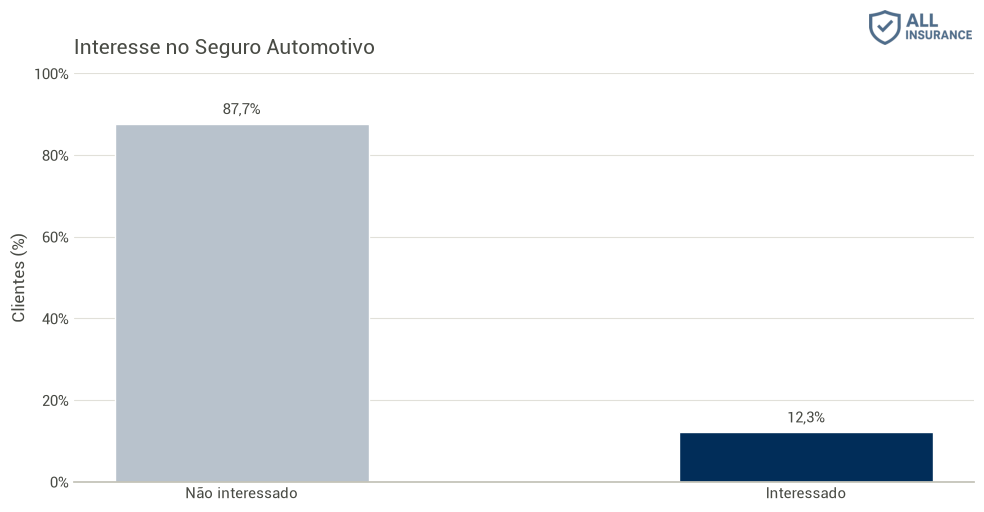

In [31]:
aux = df4['response'].value_counts( normalize=True ).sort_index()

fig, ax = plt.subplots( figsize=(10, 5) )

bars = ax.bar( ['Não interessado', 'Interessado'], aux.values, width=0.45, color=[COLOR_GRAY, COLOR_MAIN] )
ax.bar_label( bars, labels=[fmt_perc( v ) for v in aux.values], padding=4, color=COLOR_TEXT, fontsize=11 )
ax.yaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
ax.set_ylim( 0, 1 )
set_chart( ax, 'Interesse no Seguro Automotivo', '', 'Clientes (%)' )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'variavel_resposta' )

**Aprendizado: Apenas 12,3% dos clientes têm interesse no seguro automotivo. Com a base desbalanceada, a acurácia não é uma boa métrica: um modelo que classifica todos os clientes como "não interessados" acerta 87,7% das vezes e não tem nenhuma utilidade para o negócio.**

### 4.1.2. Variáveis Numéricas

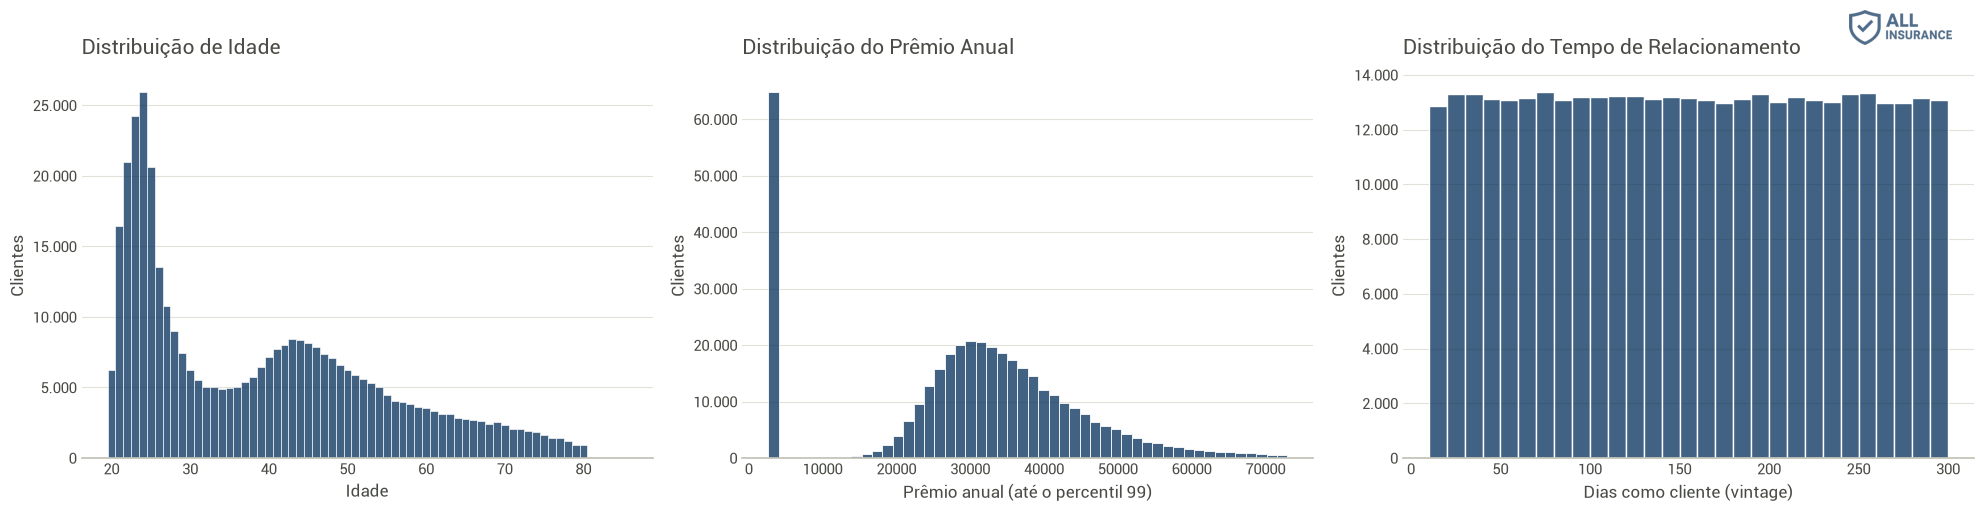

In [32]:
fig, axs = plt.subplots( 1, 3, figsize=(20, 5) )

# age: uma barra para cada idade
sns.histplot( df4['age'], discrete=True, color=COLOR_MAIN, ax=axs[0] )
set_chart( axs[0], 'Distribuição de Idade', 'Idade', 'Clientes' )

# annual_premium: limitado ao percentil 99 para facilitar a visualização
p99 = df4['annual_premium'].quantile( 0.99 )
sns.histplot( df4.loc[df4['annual_premium'] <= p99, 'annual_premium'], bins=50, color=COLOR_MAIN, ax=axs[1] )
set_chart( axs[1], 'Distribuição do Prêmio Anual', 'Prêmio anual (até o percentil 99)', 'Clientes' )

# vintage: faixas de 10 dias
sns.histplot( df4['vintage'], bins=range( 10, 301, 10 ), color=COLOR_MAIN, ax=axs[2] )
set_chart( axs[2], 'Distribuição do Tempo de Relacionamento', 'Dias como cliente (vintage)', 'Clientes' )

for ax in axs:
    ax.yaxis.set_major_formatter( mtick.FuncFormatter( lambda x, _: fmt_int( x ) ) )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'variaveis_numericas' )

### 4.1.3. Variáveis Categóricas

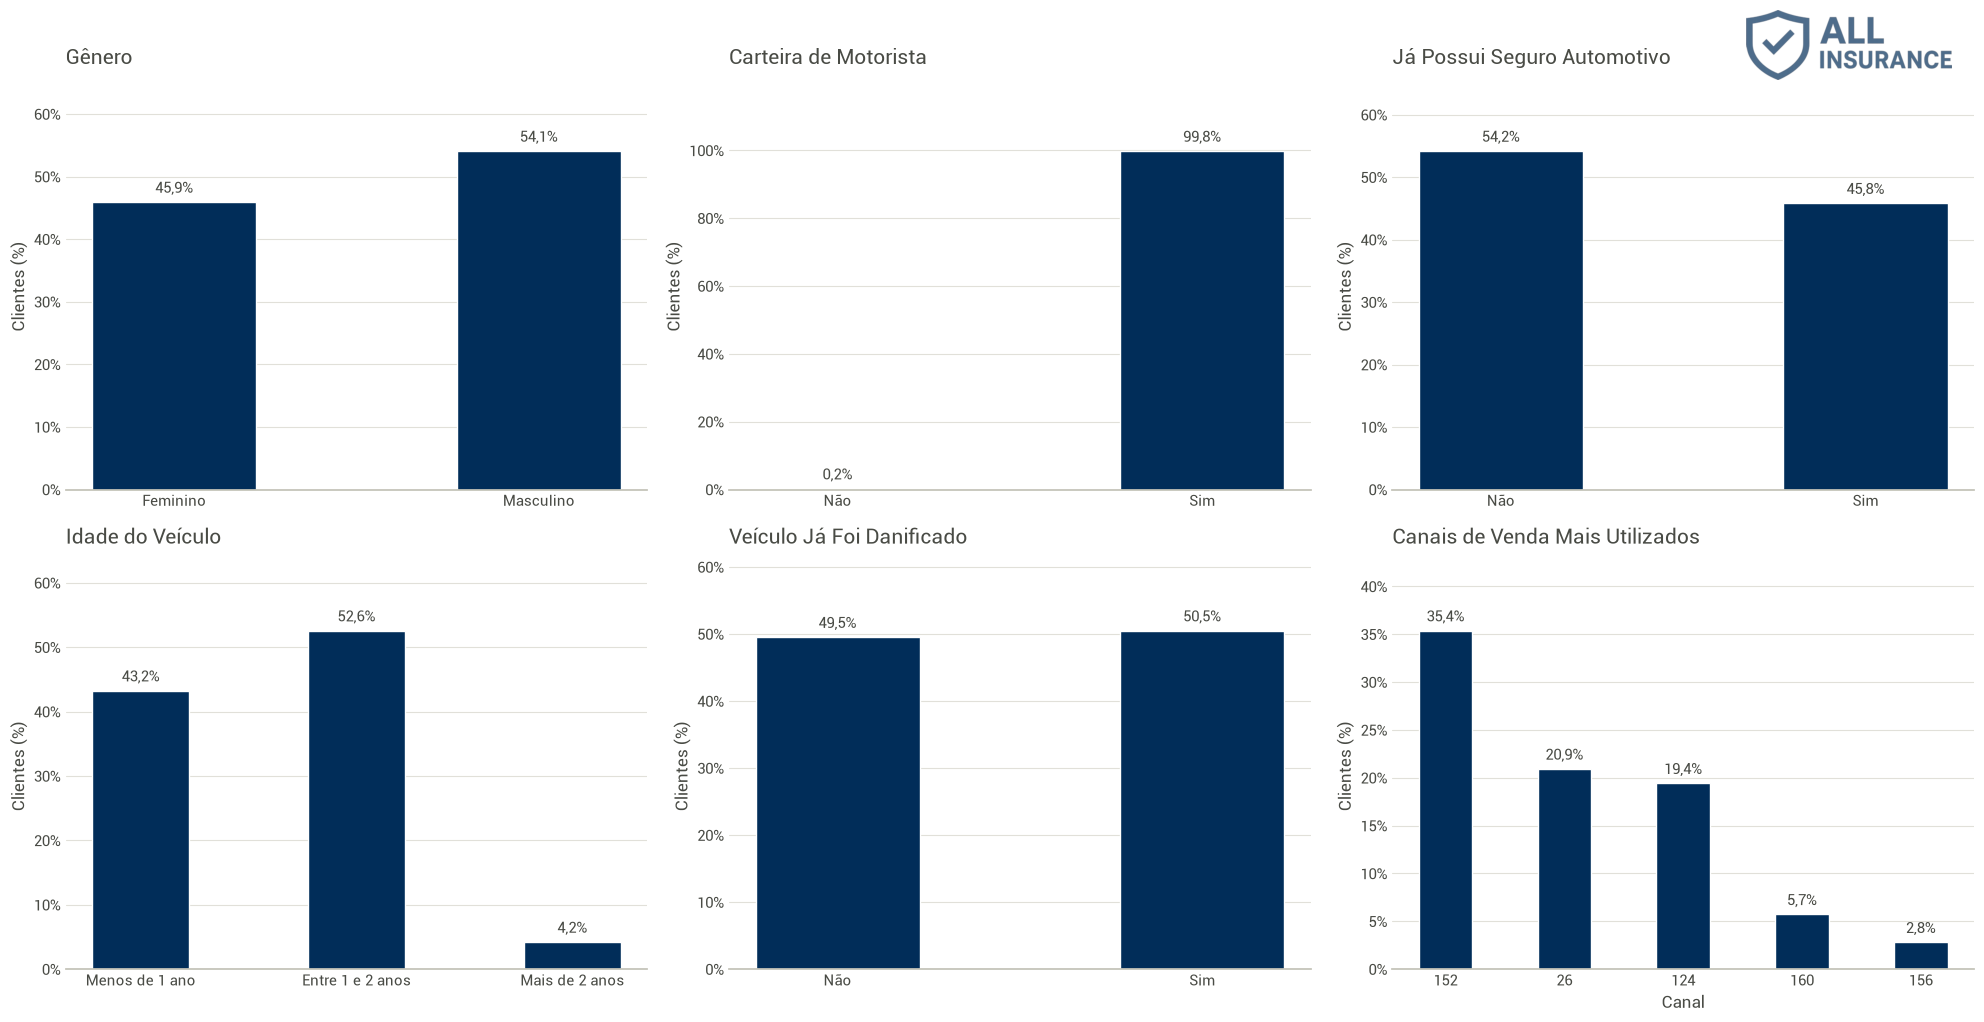

In [33]:
fig, axs = plt.subplots( 2, 3, figsize=(20, 10) )

plot_share( axs[0, 0], df4, 'gender', 'Gênero', '', order=['feminino', 'masculino'], labels=['Feminino', 'Masculino'] )
plot_share( axs[0, 1], df4, 'driving_license', 'Carteira de Motorista', '', order=[0, 1], labels=['Não', 'Sim'] )
plot_share( axs[0, 2], df4, 'previously_insured', 'Já Possui Seguro Automotivo', '', order=[0, 1], labels=['Não', 'Sim'] )
plot_share( axs[1, 0], df4, 'vehicle_age', 'Idade do Veículo', '',
            order=['menos_de_1_ano', 'entre_1_e_2_anos', 'mais_de_2_anos'], labels=['Menos de 1 ano', 'Entre 1 e 2 anos', 'Mais de 2 anos'] )
plot_share( axs[1, 1], df4, 'vehicle_damage', 'Veículo Já Foi Danificado', '', order=[0, 1], labels=['Não', 'Sim'] )

# policy_sales_channel: os 5 canais mais utilizados
top5_channels = df4['policy_sales_channel'].value_counts().head( 5 ).index.tolist()
plot_share( axs[1, 2], df4, 'policy_sales_channel', 'Canais de Venda Mais Utilizados', 'Canal', order=top5_channels )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'variaveis_categoricas' )

## 4.2. Análise Bivariada

### H1. Clientes mais velhos deveriam ter mais interesse em adquirir um seguro automotivo.

**FALSA** O interesse NÃO cresce continuamente com a idade: ele SOBE até os 50 anos e CAI a partir daí. Os clientes entre 31 e 50 anos são os mais interessados (21%), enquanto a taxa cai para 7,4% acima dos 70 anos. Os clientes de até 25 anos são os menos interessados (3,5%).

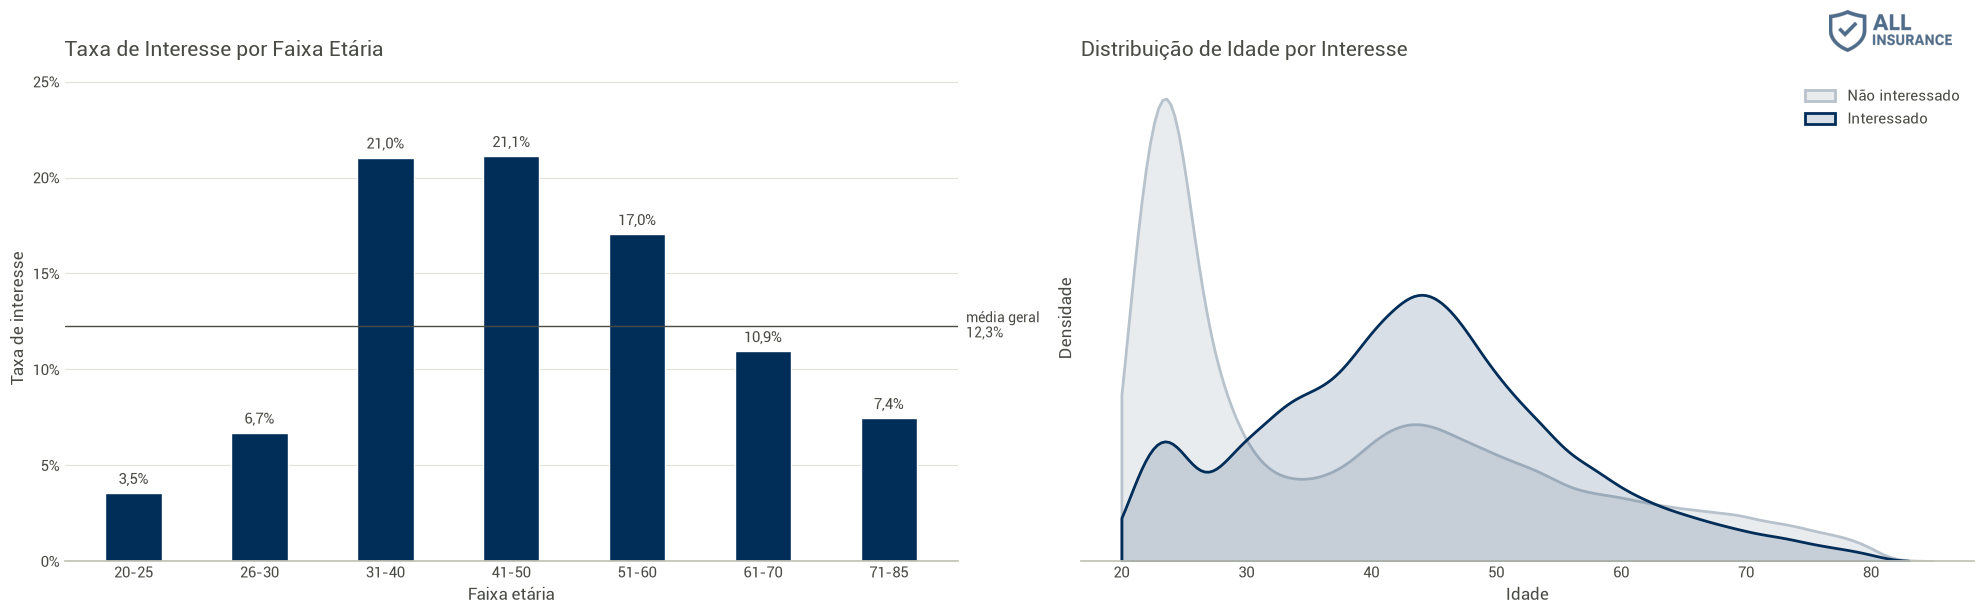

In [34]:
aux = df4[['age', 'response']].copy()
aux['age_group'] = pd.cut( aux['age'], bins=[19, 25, 30, 40, 50, 60, 70, 85], labels=['20-25', '26-30', '31-40', '41-50', '51-60', '61-70', '71-85'] )

fig, axs = plt.subplots( 1, 2, figsize=(20, 6) )

plot_rate( axs[0], aux, 'age_group', 'Taxa de Interesse por Faixa Etária', 'Faixa etária' )
plot_distribution( axs[1], df4, 'age', 'Distribuição de Idade por Interesse', 'Idade' )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h1' )

### H2. Clientes do sexo masculino deveriam ter mais interesse em adquirir um seguro automotivo.

**VERDADEIRA** Clientes do sexo MASCULINO têm MAIS interesse: 13,8% contra 10,4% das clientes do sexo feminino.

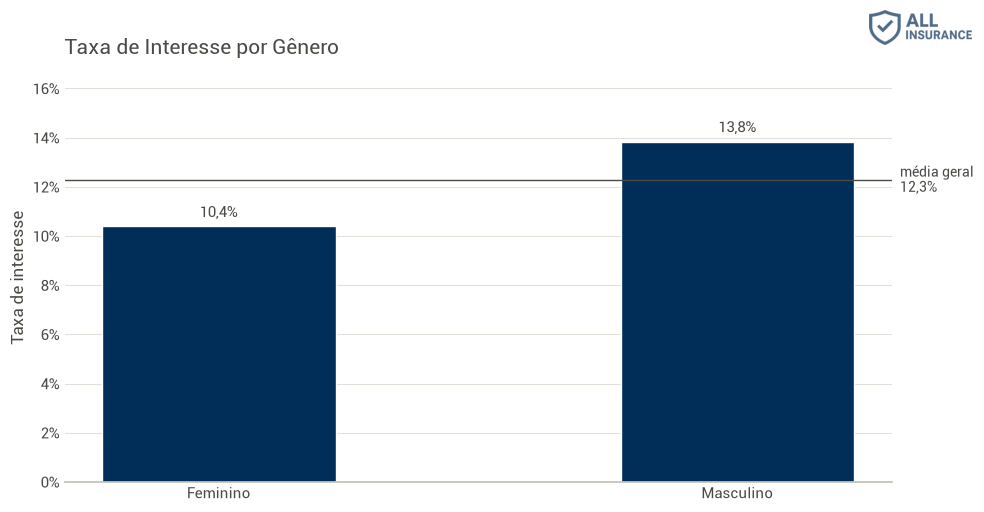

In [35]:
fig, ax = plt.subplots( figsize=(10, 5) )

plot_rate( ax, df4, 'gender', 'Taxa de Interesse por Gênero', '', order=['feminino', 'masculino'], labels=['Feminino', 'Masculino'] )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h2' )

### H3. Clientes com carteira de motorista deveriam ter mais interesse em adquirir um seguro automotivo.

**VERDADEIRA** Clientes COM carteira de motorista têm MAIS interesse (12,3% contra 5,0%). No entanto, apenas 812 clientes (0,2% da base) não possuem carteira, o que torna essa variável pouco relevante.

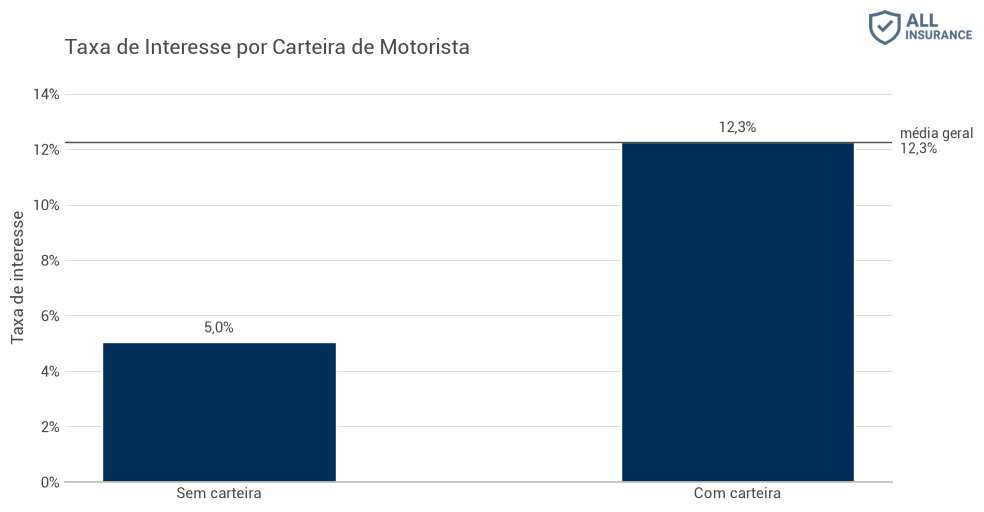

In [36]:
fig, ax = plt.subplots( figsize=(10, 5) )

plot_rate( ax, df4, 'driving_license', 'Taxa de Interesse por Carteira de Motorista', '', order=[0, 1], labels=['Sem carteira', 'Com carteira'] )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h3' )

In [37]:
df4['driving_license'].value_counts()

driving_license
1    380297
0       812
Name: count, dtype: int64

### H4. Clientes de regiões com mais clientes deveriam ter mais interesse em adquirir um seguro automotivo.

**FALSA** O número de clientes da região NÃO está relacionado ao interesse. A região 28, que concentra 28% dos clientes, tem uma das maiores taxas (18,7%), mas sem ela a correlação entre o número de clientes e a taxa de interesse das regiões é praticamente nula.

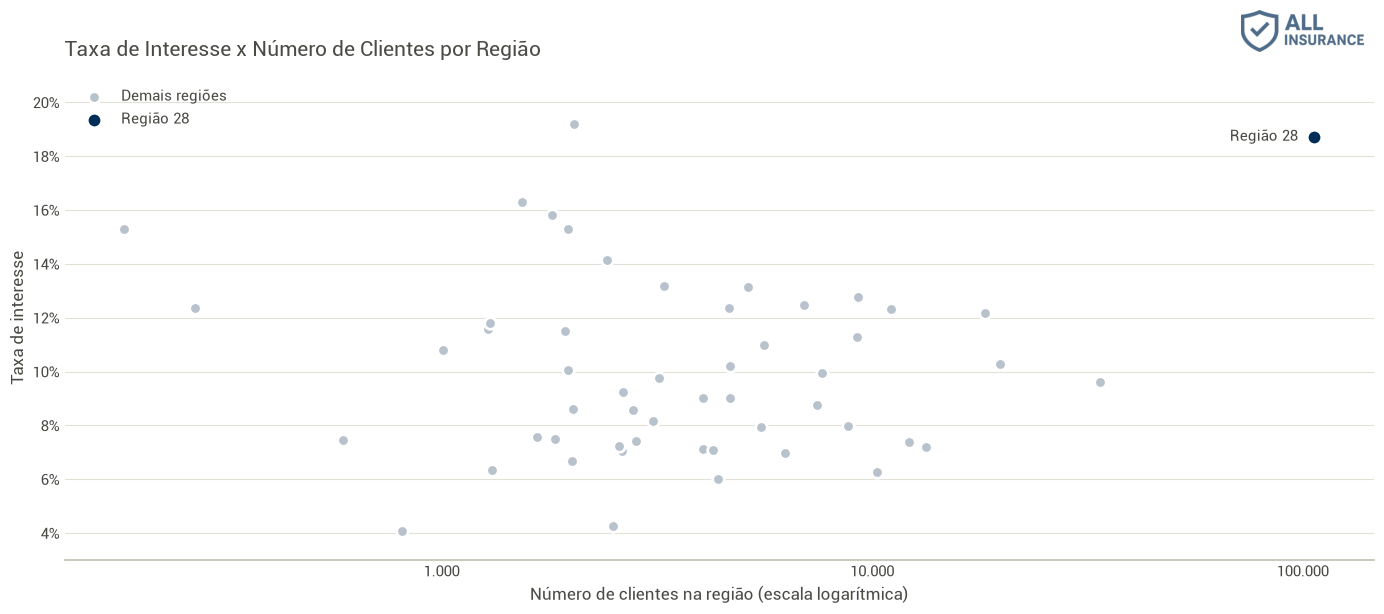

In [38]:
aux = df4[['region_code', 'response']].groupby( 'region_code' ).agg( rate=( 'response', 'mean' ), n=( 'response', 'size' ) ).reset_index()
is_28 = aux['region_code'] == 28

fig, ax = plt.subplots( figsize=(14, 6) )

ax.scatter( aux.loc[~is_28, 'n'], aux.loc[~is_28, 'rate'], s=70, color=COLOR_GRAY, edgecolor='white', linewidth=2, label='Demais regiões' )
ax.scatter( aux.loc[is_28, 'n'], aux.loc[is_28, 'rate'], s=110, color=COLOR_MAIN, edgecolor='white', linewidth=2, label='Região 28' )
ax.annotate( 'Região 28', xy=( aux.loc[is_28, 'n'].iloc[0], aux.loc[is_28, 'rate'].iloc[0] ), xytext=( -12, 0 ),
             textcoords='offset points', ha='right', va='center', fontsize=11, color=COLOR_TEXT )

ax.set_xscale( 'log' )
ax.set_ylim( 0.03, 0.21 )
ax.xaxis.set_major_formatter( mtick.FuncFormatter( lambda x, _: fmt_int( x ) ) )
ax.yaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
ax.legend( frameon=False, fontsize=11, loc='upper left' )
set_chart( ax, 'Taxa de Interesse x Número de Clientes por Região', 'Número de clientes na região (escala logarítmica)', 'Taxa de interesse' )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h4' )

In [39]:
print( f"Clientes na região 28: {fmt_perc( aux.loc[is_28, 'n'].iloc[0] / aux['n'].sum() )}" )
print( f"Correlação com a região 28: {fmt_dec( aux['n'].corr( aux['rate'] ), 2 )}" )
print( f"Correlação sem a região 28: {fmt_dec( aux.loc[~is_28, 'n'].corr( aux.loc[~is_28, 'rate'] ), 2 )}" )

Clientes na região 28: 27,9%
Correlação com a região 28: 0,31
Correlação sem a região 28: -0,05


### H5. Clientes com veículos mais novos deveriam ter mais interesse em adquirir um seguro automotivo.

**FALSA** Clientes com veículos MAIS NOVOS têm MENOS interesse. A taxa de interesse é de 4,4% para veículos com menos de 1 ano e chega a 29,4% para veículos com mais de 2 anos.

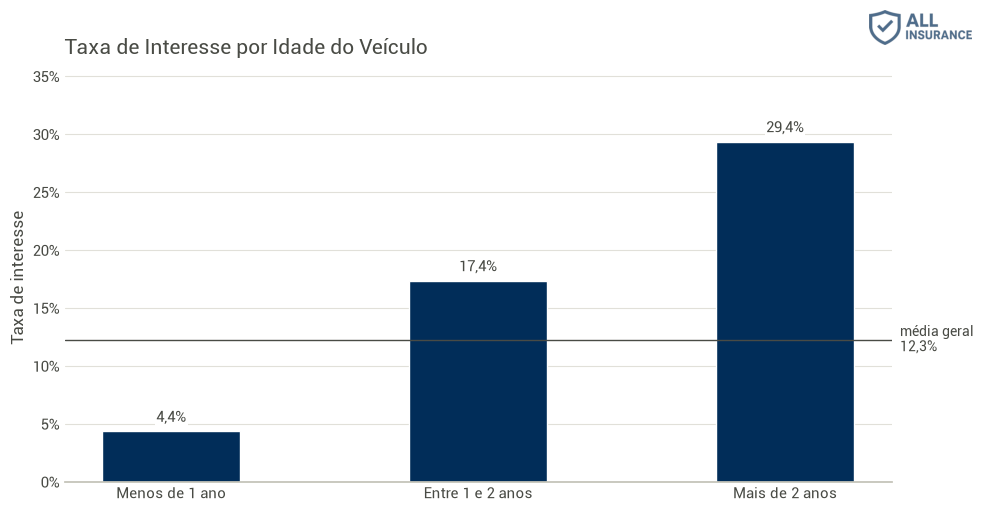

In [40]:
fig, ax = plt.subplots( figsize=(10, 5) )

plot_rate( ax, df4, 'vehicle_age', 'Taxa de Interesse por Idade do Veículo', '',
           order=['menos_de_1_ano', 'entre_1_e_2_anos', 'mais_de_2_anos'], labels=['Menos de 1 ano', 'Entre 1 e 2 anos', 'Mais de 2 anos'] )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h5' )

### H6. Clientes que já tiveram o veículo danificado deveriam ter mais interesse em adquirir um seguro automotivo.

**VERDADEIRA** Clientes que JÁ TIVERAM o veículo danificado têm MUITO MAIS interesse: 23,8% contra apenas 0,5% dos clientes sem histórico de dano.

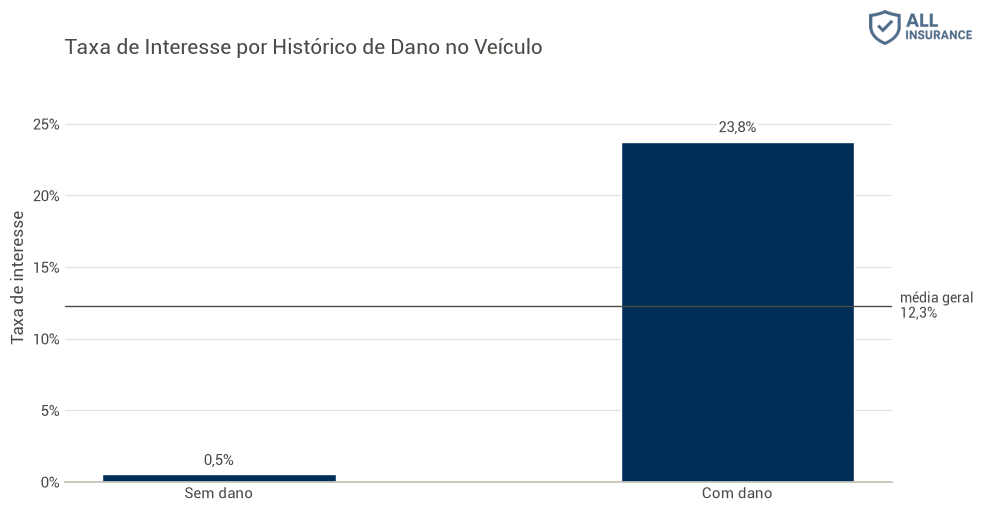

In [41]:
fig, ax = plt.subplots( figsize=(10, 5) )

plot_rate( ax, df4, 'vehicle_damage', 'Taxa de Interesse por Histórico de Dano no Veículo', '', order=[0, 1], labels=['Sem dano', 'Com dano'] )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h6' )

### H7. Clientes que já possuem seguro automotivo deveriam ter menos interesse em adquirir um seguro automotivo.

**VERDADEIRA** Clientes que JÁ POSSUEM seguro automotivo praticamente NÃO têm interesse (0,1%), enquanto 22,5% dos clientes sem seguro demonstraram interesse.

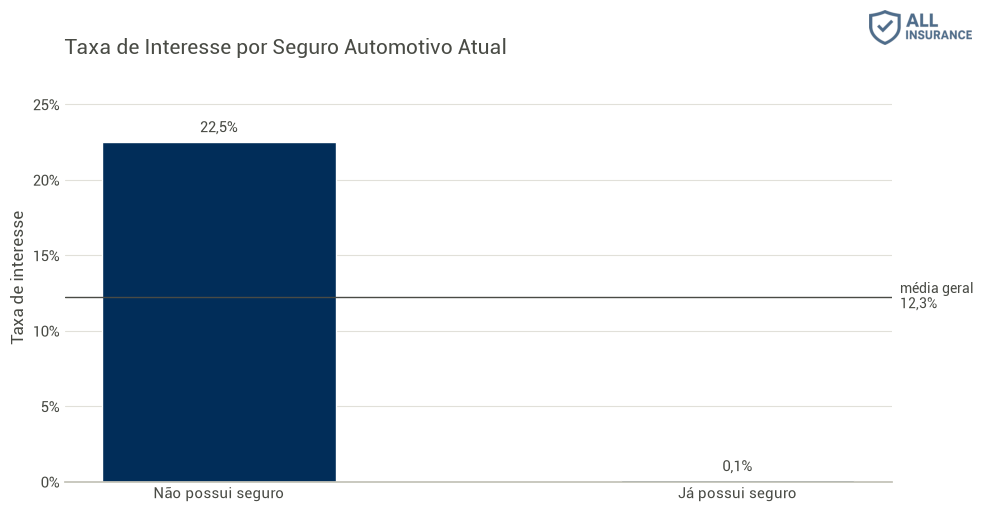

In [42]:
fig, ax = plt.subplots( figsize=(10, 5) )

plot_rate( ax, df4, 'previously_insured', 'Taxa de Interesse por Seguro Automotivo Atual', '', order=[0, 1], labels=['Não possui seguro', 'Já possui seguro'] )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h7' )

### H8. Clientes que pagam um prêmio anual maior no seguro saúde deveriam ter mais interesse em adquirir um seguro automotivo.

**VERDADEIRA** Clientes com prêmio anual MAIOR têm MAIS interesse. Desconsiderando os clientes do prêmio mínimo, a taxa de interesse sobe de 9,4% na faixa de menor prêmio para 15,0% na faixa de maior prêmio. Os clientes do prêmio mínimo (2.630) formam um grupo à parte, com taxa de 13,1%.

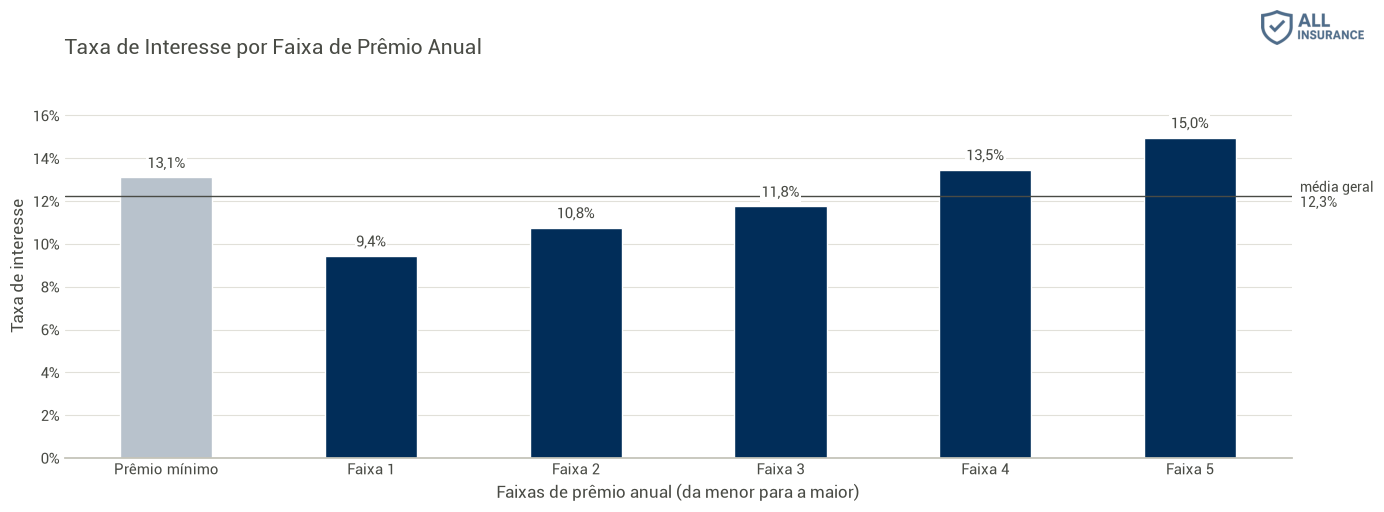

In [43]:
aux = df4[['annual_premium', 'response']].copy()

# clientes do prêmio mínimo formam um grupo à parte; os demais são divididos em 5 faixas (quintis)
aux['premium_group'] = 'Prêmio mínimo'
aux.loc[aux['annual_premium'] > min_premium, 'premium_group'] = pd.qcut( aux.loc[aux['annual_premium'] > min_premium, 'annual_premium'],
                                                                         q=5, labels=['Faixa 1', 'Faixa 2', 'Faixa 3', 'Faixa 4', 'Faixa 5'] ).astype( str )

premium_groups = ['Prêmio mínimo', 'Faixa 1', 'Faixa 2', 'Faixa 3', 'Faixa 4', 'Faixa 5']

fig, ax = plt.subplots( figsize=(14, 5) )

plot_rate( ax, aux, 'premium_group', 'Taxa de Interesse por Faixa de Prêmio Anual', 'Faixas de prêmio anual (da menor para a maior)',
           order=premium_groups, highlight=premium_groups[1:] )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h8' )

### H9. Clientes com mais tempo de relacionamento com a All Insurance deveriam ter mais interesse em adquirir um seguro automotivo.

**FALSA** O tempo de relacionamento NÃO influencia o interesse. A distribuição de `vintage` é praticamente idêntica entre interessados e não interessados, e a taxa de interesse fica entre 12,0% e 12,5% em todas as faixas.

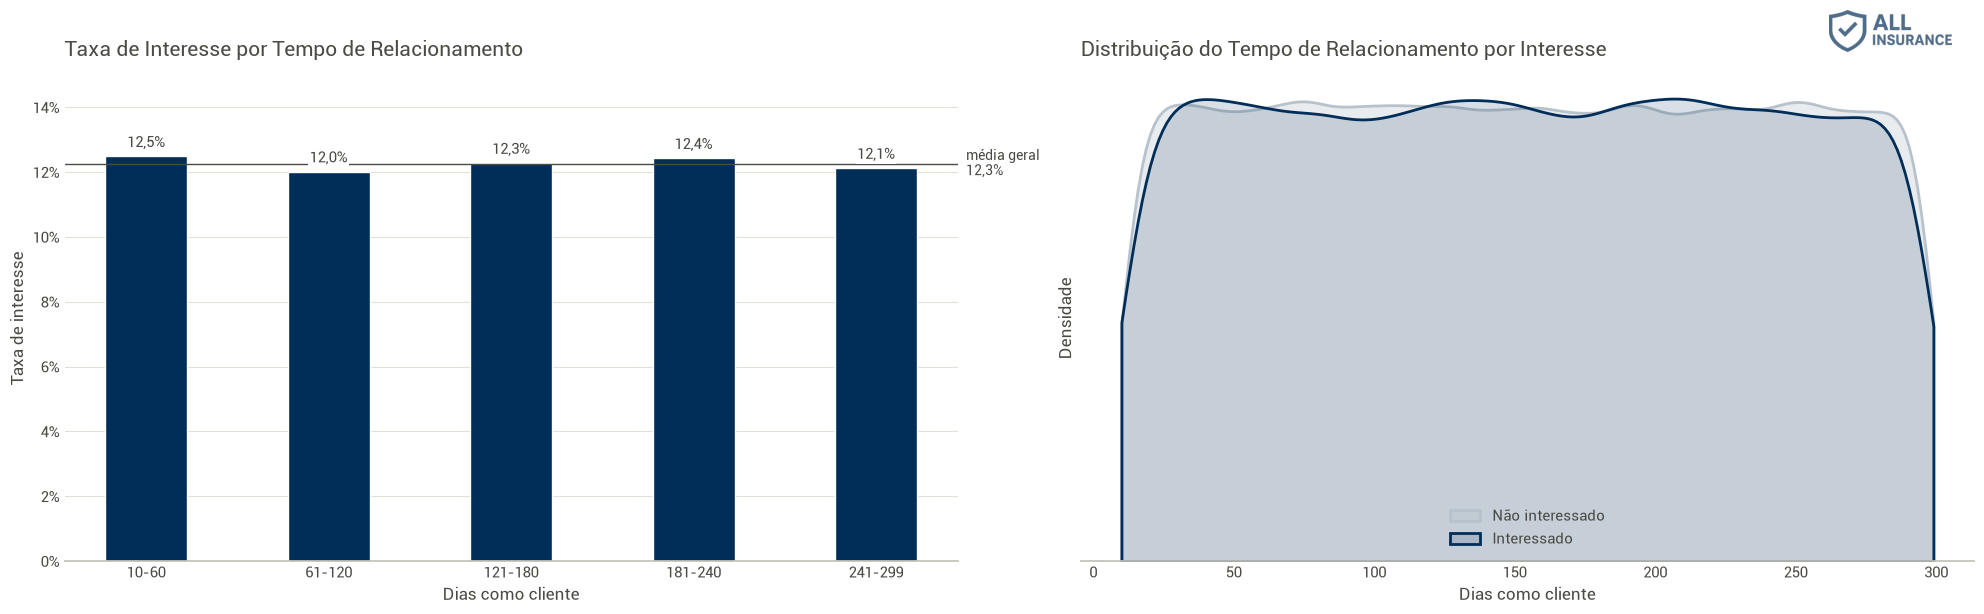

In [44]:
aux = df4[['vintage', 'response']].copy()
aux['vintage_group'] = pd.cut( aux['vintage'], bins=[9, 60, 120, 180, 240, 299], labels=['10-60', '61-120', '121-180', '181-240', '241-299'] )

fig, axs = plt.subplots( 1, 2, figsize=(20, 6) )

plot_rate( axs[0], aux, 'vintage_group', 'Taxa de Interesse por Tempo de Relacionamento', 'Dias como cliente' )
plot_distribution( axs[1], df4, 'vintage', 'Distribuição do Tempo de Relacionamento por Interesse', 'Dias como cliente' )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h9' )

### H10. Clientes captados pelos canais de venda mais utilizados deveriam ter mais interesse em adquirir um seguro automotivo.

**FALSA** O canal MAIS UTILIZADO (152), responsável por 35% dos clientes, tem uma das MENORES taxas de interesse (2,9%), assim como o canal 160 (2,2%). Já os canais 26 e 124, segundo e terceiro mais utilizados, têm taxas próximas de 20%.

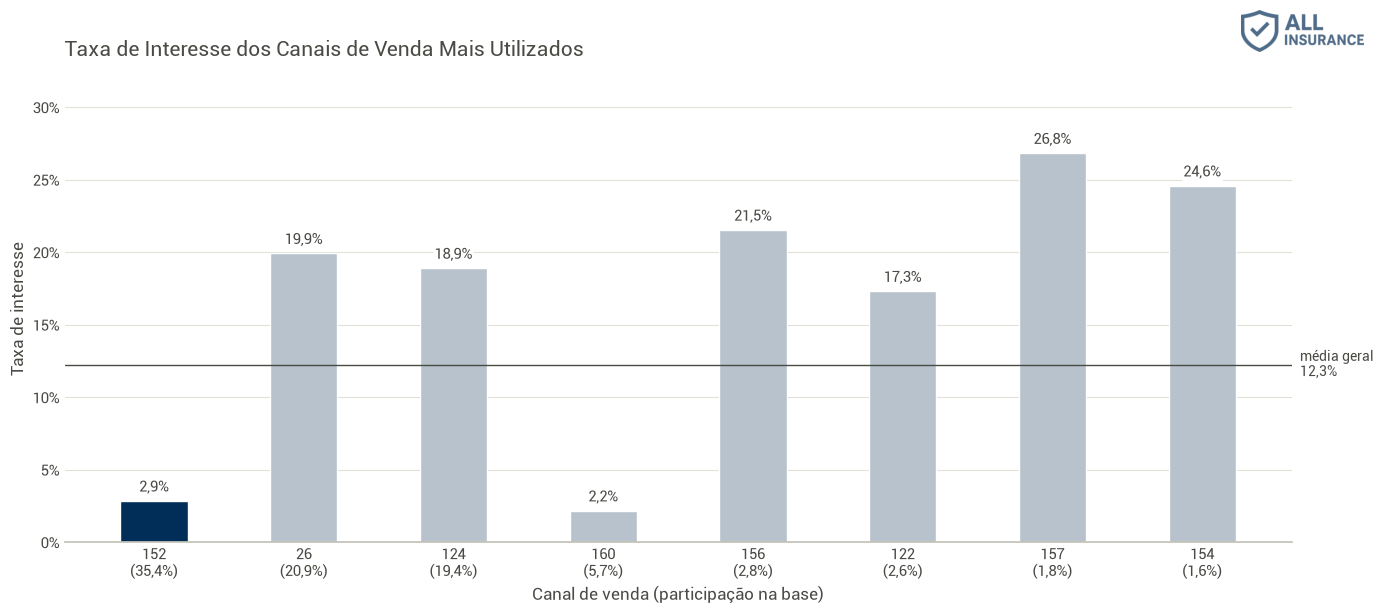

In [45]:
top8_channels = df4['policy_sales_channel'].value_counts().head( 8 ).index.tolist()
aux = df4[df4['policy_sales_channel'].isin( top8_channels )]

# rótulo com o código do canal e a participação na base
labels = [f"{c}\n({fmt_perc( ( df4['policy_sales_channel'] == c ).mean() )})" for c in top8_channels]

fig, ax = plt.subplots( figsize=(14, 6) )

plot_rate( ax, aux, 'policy_sales_channel', 'Taxa de Interesse dos Canais de Venda Mais Utilizados', 'Canal de venda (participação na base)',
           order=top8_channels, labels=labels, highlight=[152], rate_mean=df4['response'].mean() )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'h10' )

### 4.2.1. Resumo das Hipóteses

In [46]:
tab = [
    ['Hipóteses', 'Conclusão', 'Relevância'],
    ['H1', 'Falsa', 'Alta'],
    ['H2', 'Verdadeira', 'Média'],
    ['H3', 'Verdadeira', 'Baixa'],
    ['H4', 'Falsa', 'Média'],
    ['H5', 'Falsa', 'Alta'],
    ['H6', 'Verdadeira', 'Alta'],
    ['H7', 'Verdadeira', 'Alta'],
    ['H8', 'Verdadeira', 'Média'],
    ['H9', 'Falsa', 'Baixa'],
    ['H10', 'Falsa', 'Alta']]

print( tabulate( tab, headers='firstrow' ) )

Hipóteses    Conclusão    Relevância
-----------  -----------  ------------
H1           Falsa        Alta
H2           Verdadeira   Média
H3           Verdadeira   Baixa
H4           Falsa        Média
H5           Falsa        Alta
H6           Verdadeira   Alta
H7           Verdadeira   Alta
H8           Verdadeira   Média
H9           Falsa        Baixa
H10          Falsa        Alta


## 4.3. Análise Multivariada

### 4.3.1. Atributos Numéricos

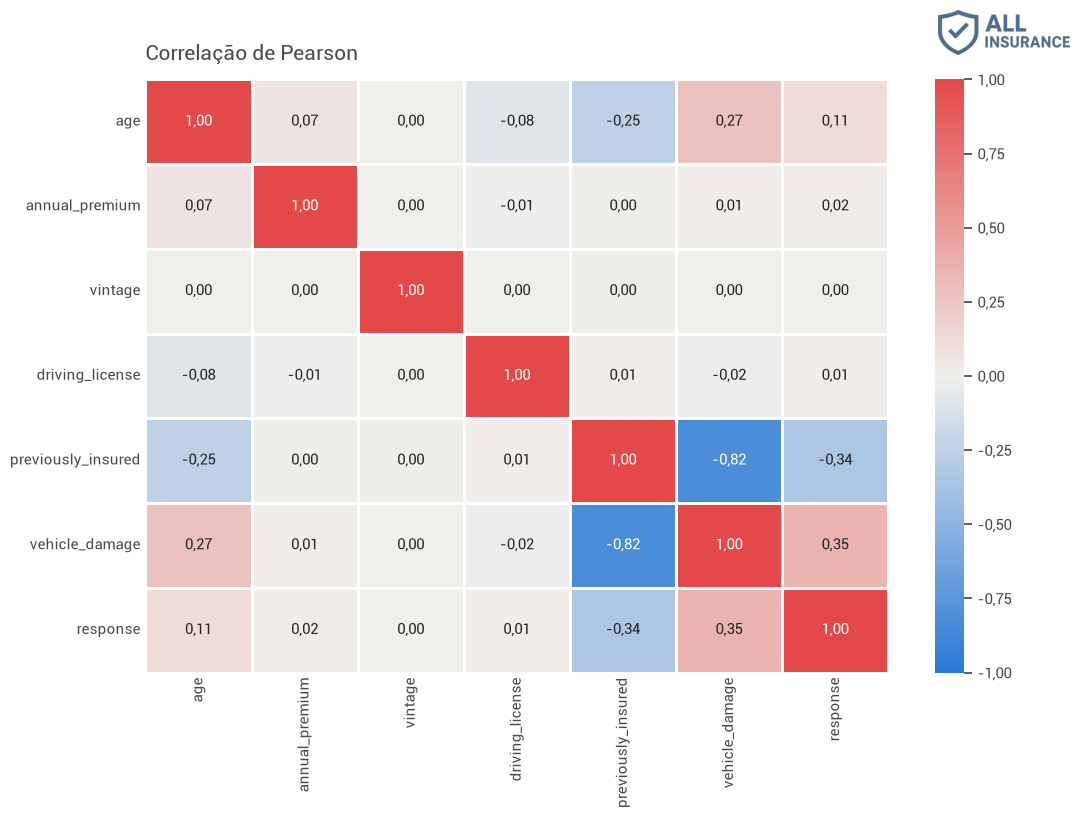

In [47]:
num_attributes = df4[['age', 'annual_premium', 'vintage', 'driving_license', 'previously_insured', 'vehicle_damage', 'response']]
correlation = num_attributes.corr( method='pearson' )

# paleta divergente: azul (correlação negativa), cinza (neutro) e vermelho (correlação positiva)
cmap_div = mcolors.LinearSegmentedColormap.from_list( 'div', ['#2a78d6', '#f0efec', '#e34948'] )

fig, ax = plt.subplots( figsize=(11, 8) )

sns.heatmap( correlation, annot=correlation.map( lambda x: fmt_dec( x, 2 ) ), fmt='', cmap=cmap_div, vmin=-1, vmax=1, linewidths=2, linecolor='white',
             annot_kws={'size': 11}, cbar_kws={'format': mtick.FuncFormatter( lambda x, _: fmt_dec( x, 2 ) )}, ax=ax )
ax.set_title( 'Correlação de Pearson', fontsize=15, color=COLOR_TEXT, loc='left', pad=14 )
ax.tick_params( length=0, labelsize=11 )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'correlacao_numericas' )

### 4.3.2. Atributos Categóricos

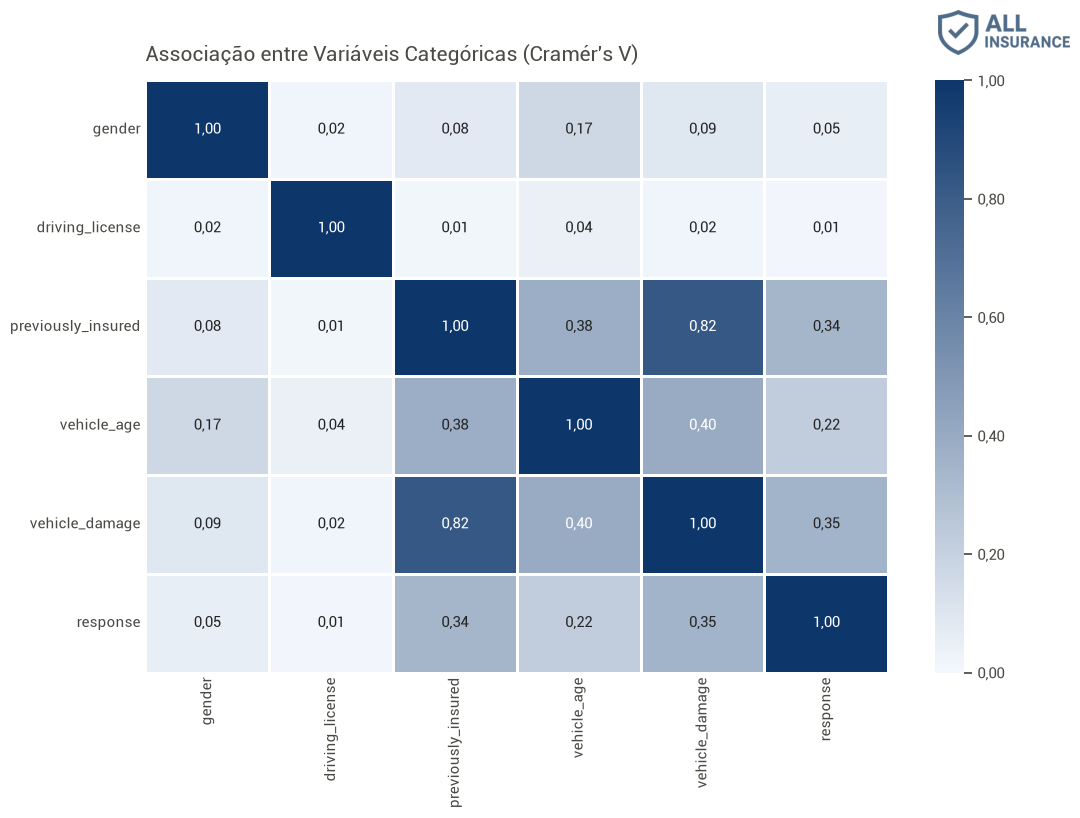

In [48]:
cat_cols = ['gender', 'driving_license', 'previously_insured', 'vehicle_age', 'vehicle_damage', 'response']

# Cramér's V entre cada par de variáveis categóricas
cramer = pd.DataFrame( [[cramer_v( df4[c1], df4[c2] ) for c2 in cat_cols] for c1 in cat_cols], index=cat_cols, columns=cat_cols )

# paleta sequencial: um único tom de azul, do claro (0) ao escuro (1)
cmap_seq = mcolors.LinearSegmentedColormap.from_list( 'seq', ['#f4f8fd', '#0d366b'] )

fig, ax = plt.subplots( figsize=(11, 8) )

sns.heatmap( cramer, annot=cramer.map( lambda x: fmt_dec( x, 2 ) ), fmt='', cmap=cmap_seq, vmin=0, vmax=1, linewidths=2, linecolor='white',
             annot_kws={'size': 11}, cbar_kws={'format': mtick.FuncFormatter( lambda x, _: fmt_dec( x, 2 ) )}, ax=ax )
ax.set_title( "Associação entre Variáveis Categóricas (Cramér's V)", fontsize=15, color=COLOR_TEXT, loc='left', pad=14 )
ax.tick_params( length=0, labelsize=11 )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'correlacao_categoricas' )

**OBS.: `previously_insured` e `vehicle_damage` são as variáveis mais associadas à resposta e também fortemente associadas entre si: clientes que já possuem seguro automotivo raramente declaram dano no veículo.**

# 5.0. PREPARAÇÃO DOS DADOS

In [49]:
df5 = df4.copy()

del df3

## 5.1. Separação entre Treino e Teste

A base é separada em treino (80%) e teste (20%) **antes** da preparação dos dados. Assim, os scalers e encoders aprendem apenas com os dados de treino e a base de teste simula clientes nunca vistos pelo modelo, evitando o vazamento de dados (*data leakage*). A separação é estratificada para manter a mesma proporção de interessados nas duas bases.

In [50]:
X = df5.drop( 'response', axis=1 )
y = df5['response'].copy()

x_train, x_test, y_train, y_test = ms.train_test_split( X, y, test_size=0.2, stratify=y, random_state=42 )

print( f'Treino: {fmt_int( x_train.shape[0] )} clientes | Taxa de interesse: {fmt_perc( y_train.mean(), 2 )}' )
print( f'Teste: {fmt_int( x_test.shape[0] )} clientes | Taxa de interesse: {fmt_perc( y_test.mean(), 2 )}' )

Treino: 304.887 clientes | Taxa de interesse: 12,26%
Teste: 76.222 clientes | Taxa de interesse: 12,26%


## 5.2. Rescaling

In [51]:
rs = pp.RobustScaler()
mms_age = pp.MinMaxScaler()
mms_vintage = pp.MinMaxScaler()

# annual_premium - Robust Scaler: variável com muitos outliers
x_train['annual_premium'] = rs.fit_transform( x_train[['annual_premium']].values )
x_test['annual_premium'] = rs.transform( x_test[['annual_premium']].values )
pickle.dump( rs, open( '../api/parameter/annual_premium_scaler.pkl', 'wb' ) )

# age - Min-Max Scaler
x_train['age'] = mms_age.fit_transform( x_train[['age']].values )
x_test['age'] = mms_age.transform( x_test[['age']].values )
pickle.dump( mms_age, open( '../api/parameter/age_scaler.pkl', 'wb' ) )

# vintage - Min-Max Scaler
x_train['vintage'] = mms_vintage.fit_transform( x_train[['vintage']].values )
x_test['vintage'] = mms_vintage.transform( x_test[['vintage']].values )

## 5.3. Encoding

Para `region_code` e `policy_sales_channel`, que possuem muitas categorias (53 regiões e 155 canais de venda), foi utilizado o `TargetEncoder` do scikit-learn. Ele substitui cada categoria pela taxa de interesse daquela categoria, com uma suavização para as categorias com poucos clientes. No treino, o `fit_transform` utiliza *cross fitting*: o valor de cada cliente é calculado com folds dos quais ele não faz parte, para que o encoding não carregue a resposta do próprio cliente.

In [52]:
# gender - Binary Encoding
gender_encoding = { 'feminino': 0, 'masculino': 1 }
x_train['gender'] = x_train['gender'].map( gender_encoding )
x_test['gender'] = x_test['gender'].map( gender_encoding )

# vehicle_age - Ordinal Encoding
vehicle_age_encoding = { 'menos_de_1_ano': 0, 'entre_1_e_2_anos': 1, 'mais_de_2_anos': 2 }
x_train['vehicle_age'] = x_train['vehicle_age'].map( vehicle_age_encoding )
x_test['vehicle_age'] = x_test['vehicle_age'].map( vehicle_age_encoding )

# region_code - Target Encoding
te_region_code = pp.TargetEncoder( target_type='binary', cv=ms.StratifiedKFold( n_splits=5, shuffle=True, random_state=42 ) )
x_train['region_code'] = te_region_code.fit_transform( x_train[['region_code']], y_train )
x_test['region_code'] = te_region_code.transform( x_test[['region_code']] )
pickle.dump( te_region_code, open( '../api/parameter/region_code_encoder.pkl', 'wb' ) )

# policy_sales_channel - Target Encoding
te_policy_sales_channel = pp.TargetEncoder( target_type='binary', cv=ms.StratifiedKFold( n_splits=5, shuffle=True, random_state=42 ) )
x_train['policy_sales_channel'] = te_policy_sales_channel.fit_transform( x_train[['policy_sales_channel']], y_train )
x_test['policy_sales_channel'] = te_policy_sales_channel.transform( x_test[['policy_sales_channel']] )
pickle.dump( te_policy_sales_channel, open( '../api/parameter/policy_sales_channel_encoder.pkl', 'wb' ) )

x_train.head()

,id_cliente,gender,age,region_code,driving_license,previously_insured,annual_premium,policy_sales_channel,vintage,vehicle_age,vehicle_damage
274710,274711,1,0.030769,0.111934,1,0,-0.415027,0.028782,0.667820,0,1
216539,216540,0,0.092308,0.096747,1,1,0.445213,0.199469,0.121107,0,0
78983,78984,0,0.184615,0.187705,1,0,0.027992,0.175703,0.086505,0,1
218368,218369,1,0.184615,0.077901,1,0,0.399867,0.028992,0.709343,0,1
307215,307216,0,0.061538,0.186392,1,0,1.130918,0.211894,0.733564,0,1


# 6.0. SELEÇÃO DE FEATURES

## 6.1. Importância das Features com Extra Trees

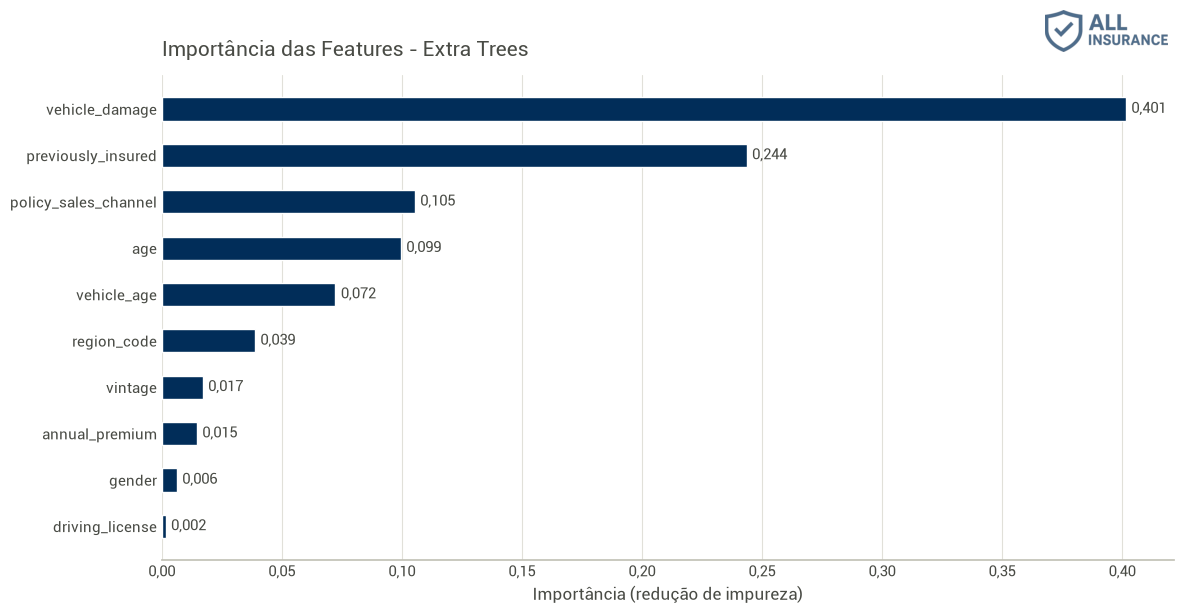

In [53]:
# features candidatas: todas, exceto o identificador do cliente
cols_candidates = x_train.drop( 'id_cliente', axis=1 ).columns.tolist()

# modelo
et = en.ExtraTreesClassifier( n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1 )
et.fit( x_train[cols_candidates], y_train )

# importância das features
df_importance = pd.DataFrame( { 'feature': cols_candidates, 'importance': et.feature_importances_ } ).sort_values( 'importance' )

fig, ax = plt.subplots( figsize=(12, 6) )

bars = ax.barh( df_importance['feature'], df_importance['importance'], height=0.5, color=COLOR_MAIN )
ax.bar_label( bars, labels=[fmt_dec( v, 3 ) for v in df_importance['importance']], padding=4, color=COLOR_TEXT, fontsize=11 )
set_chart( ax, 'Importância das Features - Extra Trees', 'Importância (redução de impureza)', '' )
ax.xaxis.set_major_formatter( mtick.FuncFormatter( lambda x, _: fmt_dec( x, 2 ) ) )
ax.grid( axis='y', visible=False )
ax.grid( axis='x', color=COLOR_GRID, linewidth=0.8 )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'importancia_extra_trees' )

As variáveis `vehicle_damage` e `previously_insured` são as mais importantes, seguidas por `policy_sales_channel`, `age` e `vehicle_age`. Como a importância por redução de impureza tende a favorecer variáveis contínuas e com muitos valores distintos, a importância também foi calculada por permutação: cada feature é embaralhada e mede-se o quanto a performance do modelo cai em uma base de validação.

## 6.2. Importância por Permutação

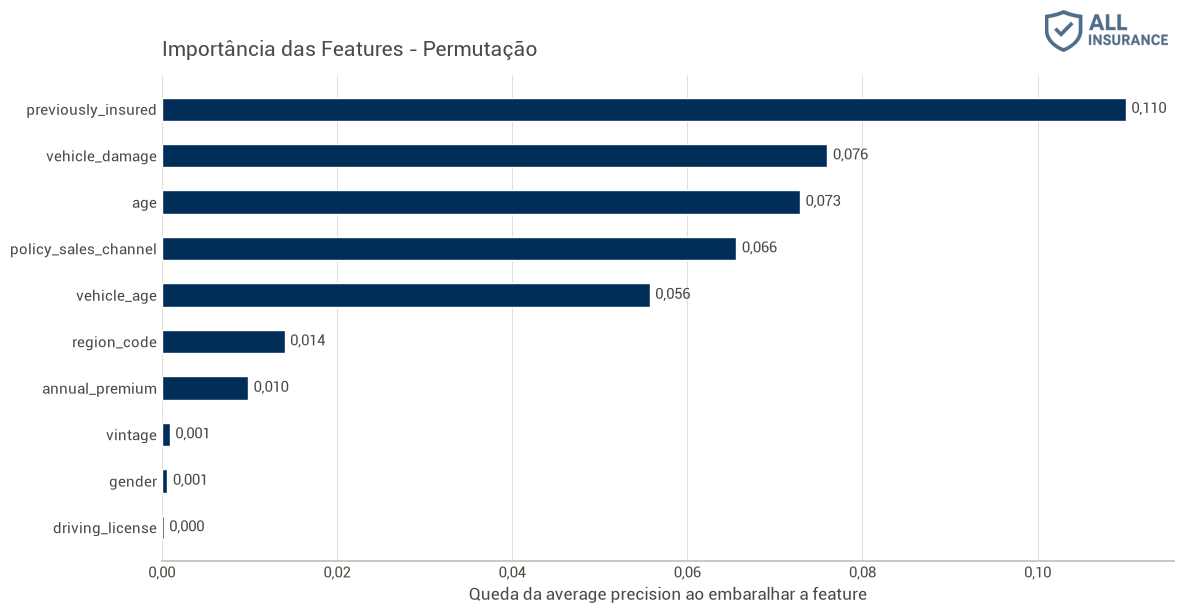

In [54]:
# parte do treino é separada para medir a importância por permutação
x_fs_train, x_fs_val, y_fs_train, y_fs_val = ms.train_test_split( x_train[cols_candidates], y_train, test_size=0.2, stratify=y_train, random_state=42 )

# modelo
lgbm_fs = lgb.LGBMClassifier( n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1 )
lgbm_fs.fit( x_fs_train, y_fs_train )

# queda da performance ( average precision ) ao embaralhar cada feature
perm = it.permutation_importance( lgbm_fs, x_fs_val, y_fs_val, scoring='average_precision', n_repeats=5, random_state=42 )
df_perm = pd.DataFrame( { 'feature': cols_candidates, 'importance': perm.importances_mean } ).sort_values( 'importance' )

fig, ax = plt.subplots( figsize=(12, 6) )

bars = ax.barh( df_perm['feature'], df_perm['importance'], height=0.5, color=COLOR_MAIN )
ax.bar_label( bars, labels=[fmt_dec( v, 3 ) for v in df_perm['importance']], padding=4, color=COLOR_TEXT, fontsize=11 )
set_chart( ax, 'Importância das Features - Permutação', 'Queda da average precision ao embaralhar a feature', '' )
ax.xaxis.set_major_formatter( mtick.FuncFormatter( lambda x, _: fmt_dec( x, 2 ) ) )
ax.grid( axis='y', visible=False )
ax.grid( axis='x', color=COLOR_GRID, linewidth=0.8 )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'importancia_permutacao' )

## 6.3. Seleção Manual de Features

As duas abordagens apontam as mesmas features como as mais importantes. A variável `vintage` foi removida: a hipótese H9 mostrou que ela não tem relação com o interesse do cliente e sua importância por permutação é praticamente nula. `gender` e `driving_license` também têm importância baixa, mas foram mantidas por apresentarem relação com o interesse na análise exploratória (H2 e H3).

In [55]:
cols_selected = ['age', 'gender', 'driving_license', 'region_code', 'previously_insured',
                 'annual_premium', 'policy_sales_channel', 'vehicle_age', 'vehicle_damage']

x_train_model = x_train[cols_selected]
x_test_model = x_test[cols_selected]

# 7.0. MODELOS DE MACHINE LEARNING

O objetivo do modelo é **ordenar** a base de clientes para o time de vendas. Por isso, as métricas de avaliação são métricas de ranqueamento:

- **Precision@K:** dos K clientes no topo da lista, quantos têm interesse no seguro automotivo.
- **Recall@K:** do total de clientes interessados, quantos estão entre os K primeiros da lista.

Como o time de vendas consegue fazer 20.000 ligações em uma base de 127.037 novos clientes, o K corresponde a **15,74% da base avaliada**. Os modelos são comparados com Cross Validation estratificado (5 folds) na base de treino. A base de teste fica reservada para a avaliação final do modelo escolhido.

## 7.1. Random Model

Modelo de referência (baseline): representa o time de vendas ligando para os clientes sem nenhum critério.

In [56]:
# score aleatório para cada cliente
np.random.seed( 42 )
yhat_random = np.random.rand( len( y_train ) )

# performance
random_result = ml_metrics( 'Random Model', y_train, yhat_random, PERC_CALLS )
random_result

,Model Name,Precision@K,Recall@K,ROC AUC
0,Random Model,0.122044,0.156765,0.499021


## 7.2. Logistic Regression

In [57]:
# modelo
lr = lm.LogisticRegression( max_iter=1000, random_state=42 )

# performance - cross validation
lr_result_cv, yhat_lr = cross_validation( 'Logistic Regression', lr, x_train_model, y_train, 5, PERC_CALLS )
lr_result_cv

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV
0,Logistic Regression,0.3412 ± 0.0035,0.4383 ± 0.0045,0.8437 ± 0.0018


## 7.3. KNN

In [58]:
# modelo
knn = nh.KNeighborsClassifier( n_neighbors=50, n_jobs=-1 )

# performance - cross validation
knn_result_cv, yhat_knn = cross_validation( 'KNN', knn, x_train_model, y_train, 5, PERC_CALLS )
knn_result_cv

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV
0,KNN,0.3475 ± 0.0040,0.4463 ± 0.0051,0.8445 ± 0.0016


## 7.4. Extra Trees

In [59]:
# modelo
et = en.ExtraTreesClassifier( n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1 )

# performance - cross validation
et_result_cv, yhat_et = cross_validation( 'Extra Trees', et, x_train_model, y_train, 5, PERC_CALLS )
et_result_cv

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV
0,Extra Trees,0.3691 ± 0.0036,0.4740 ± 0.0046,0.8555 ± 0.0018


## 7.5. Random Forest

In [60]:
# modelo
rf = en.RandomForestClassifier( n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1 )

# performance - cross validation
rf_result_cv, yhat_rf = cross_validation( 'Random Forest', rf, x_train_model, y_train, 5, PERC_CALLS )
rf_result_cv

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV
0,Random Forest,0.3574 ± 0.0036,0.4591 ± 0.0047,0.8506 ± 0.0019


## 7.6. XGBoost

In [61]:
# modelo
xgb_model = xgb.XGBClassifier( n_estimators=300, learning_rate=0.05, max_depth=6, eval_metric='logloss', random_state=42, n_jobs=-1 )

# performance - cross validation
xgb_result_cv, yhat_xgb = cross_validation( 'XGBoost', xgb_model, x_train_model, y_train, 5, PERC_CALLS )
xgb_result_cv

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV
0,XGBoost,0.3710 ± 0.0048,0.4766 ± 0.0062,0.8567 ± 0.0023


## 7.7. LightGBM

In [62]:
# modelo
lgbm = lgb.LGBMClassifier( n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1, n_jobs=-1 )

# performance - cross validation
lgbm_result_cv, yhat_lgbm = cross_validation( 'LightGBM', lgbm, x_train_model, y_train, 5, PERC_CALLS )
lgbm_result_cv

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV
0,LightGBM,0.3710 ± 0.0052,0.4765 ± 0.0067,0.8569 ± 0.0021


## 7.8. Comparação da Performance dos Modelos

In [63]:
random_row = pd.DataFrame( {
    'Model Name': 'Random Model',
    'Precision@K CV': f"{random_result.loc[0, 'Precision@K']:.4f}",
    'Recall@K CV': f"{random_result.loc[0, 'Recall@K']:.4f}",
    'ROC AUC CV': f"{random_result.loc[0, 'ROC AUC']:.4f}"}, index=[0] )

modelling_result = pd.concat( [lr_result_cv, knn_result_cv, et_result_cv, rf_result_cv, xgb_result_cv, lgbm_result_cv, random_row] )
modelling_result.sort_values( 'Recall@K CV', ascending=False ).reset_index( drop=True )

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV
0,XGBoost,0.3710 ± 0.0048,0.4766 ± 0.0062,0.8567 ± 0.0023
1,LightGBM,0.3710 ± 0.0052,0.4765 ± 0.0067,0.8569 ± 0.0021
2,Extra Trees,0.3691 ± 0.0036,0.4740 ± 0.0046,0.8555 ± 0.0018
3,Random Forest,0.3574 ± 0.0036,0.4591 ± 0.0047,0.8506 ± 0.0019
4,KNN,0.3475 ± 0.0040,0.4463 ± 0.0051,0.8445 ± 0.0016
5,Logistic Regression,0.3412 ± 0.0035,0.4383 ± 0.0045,0.8437 ± 0.0018
6,Random Model,0.1220,0.1568,0.4990


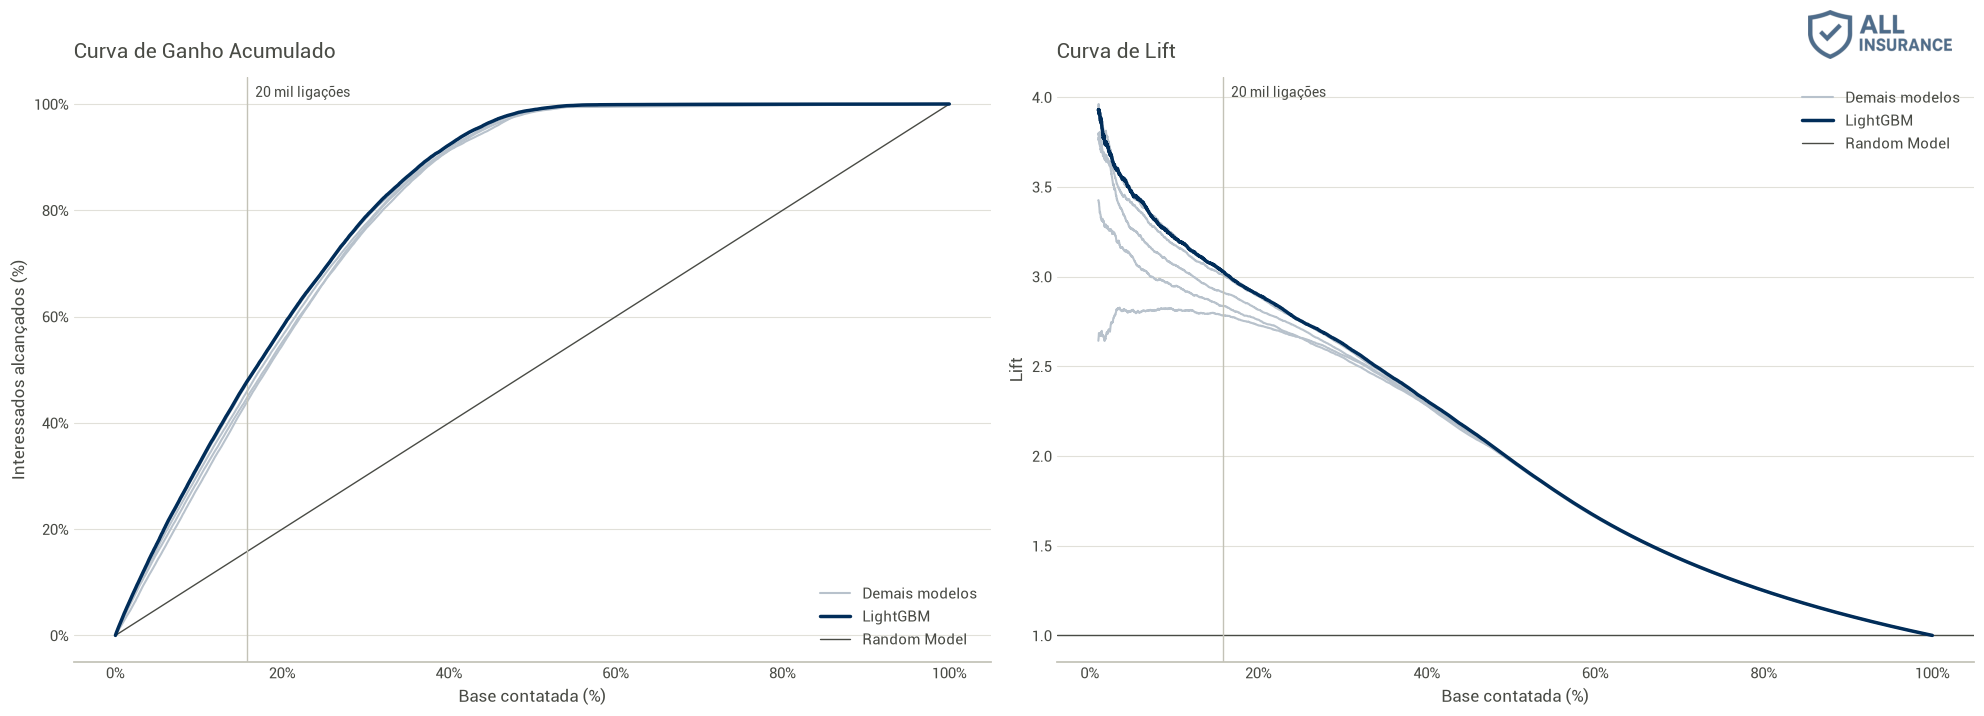

In [64]:
yhat_models = {
    'Logistic Regression': yhat_lr,
    'KNN': yhat_knn,
    'Extra Trees': yhat_et,
    'Random Forest': yhat_rf,
    'XGBoost': yhat_xgb,
    'LightGBM': yhat_lgbm }

fig, axs = plt.subplots( 1, 2, figsize=(20, 7) )

for name, yhat in yhat_models.items():
    gain = cumulative_gain( y_train, yhat ).iloc[::50]

    is_chosen = name == 'LightGBM'
    color = COLOR_MAIN if is_chosen else COLOR_GRAY
    linewidth = 2.5 if is_chosen else 1.5
    label = name if is_chosen else ( 'Demais modelos' if name == 'Logistic Regression' else None )

    # curva de ganho acumulado
    axs[0].plot( gain['perc_base'], gain['perc_interessados'], color=color, linewidth=linewidth, label=label, zorder=3 if is_chosen else 2 )

    # curva de lift: a partir de 1% da base, onde o lift deixa de oscilar
    gain = gain[gain['perc_base'] >= 0.01]
    axs[1].plot( gain['perc_base'], gain['lift'], color=color, linewidth=linewidth, label=label, zorder=3 if is_chosen else 2 )

# modelo aleatório
axs[0].plot( [0, 1], [0, 1], color=COLOR_TEXT, linewidth=1, label='Random Model' )
axs[1].axhline( 1, color=COLOR_TEXT, linewidth=1, label='Random Model' )

for ax in axs:
    ax.axvline( PERC_CALLS, color=COLOR_AXIS, linewidth=1 )
    ax.annotate( '20 mil ligações', xy=( PERC_CALLS, 1 ), xycoords=( 'data', 'axes fraction' ), xytext=( 6, -6 ),
                 textcoords='offset points', ha='left', va='top', fontsize=10, color=COLOR_TEXT )
    ax.xaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
    ax.legend( frameon=False, fontsize=11 )

axs[0].yaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
set_chart( axs[0], 'Curva de Ganho Acumulado', 'Base contatada (%)', 'Interessados alcançados (%)' )
set_chart( axs[1], 'Curva de Lift', 'Base contatada (%)', 'Lift' )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'comparacao_modelos' )

In [65]:
# tempo de treinamento e tamanho do modelo: XGBoost x LightGBM
for name, model in [( 'XGBoost', xgb_model ), ( 'LightGBM', lgbm )]:
    start = time.time()
    m = clone( model ).fit( x_train_model, y_train )
    print( f'{name}: treinamento em {fmt_dec( time.time() - start )} segundos | modelo com {fmt_dec( len( pickle.dumps( m ) ) / 1e6, 2 )} MB' )

XGBoost: treinamento em 90,1 segundos | modelo com 1,16 MB


LightGBM: treinamento em 74,2 segundos | modelo com 1,05 MB


Os modelos baseados em árvores com boosting (**XGBoost** e **LightGBM**) apresentaram os melhores resultados. Ambos alcançam cerca de 3 vezes mais interessados do que o Random Model com a mesma quantidade de ligações. O **LightGBM** foi o escolhido para seguir para o Hyperparameter Fine Tuning: a performance é equivalente à do XGBoost, mas o treinamento foi mais rápido e o modelo final é um pouco menor, o que agiliza o Fine Tuning e facilita a manutenção da API em produção.

# 8.0. HYPERPARAMETER FINE TUNING

## 8.1. Random Search

Como o K é fixo, Precision@K e Recall@K são proporcionais e levam à mesma escolha de parâmetros. A seleção foi feita pelo maior Recall@K médio do Cross Validation e, em caso de empate, pelo maior ROC AUC médio.

In [66]:
param = {
    'n_estimators': [200, 400, 600],
    'learning_rate': [0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 63],
    'min_child_samples': [20, 50, 100],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [0, 1, 5] }

MAX_EVAL = 10

In [67]:
final_result = pd.DataFrame()
hp_list = list()

random.seed( 42 )

for i in range( MAX_EVAL ):
    # escolhendo valores para os parâmetros aleatoriamente
    hp = { k: random.sample( v, 1 )[0] for k, v in param.items() }
    hp_list.append( hp )
    print( hp )

    # modelo
    model_lgbm = lgb.LGBMClassifier( **hp, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1 )

    # performance
    result, _ = cross_validation( 'LightGBM', model_lgbm, x_train_model, y_train, 5, PERC_CALLS )
    final_result = pd.concat( [final_result, pd.concat( [result, pd.DataFrame( hp, index=[0] )], axis=1 )], ignore_index=True )

{'n_estimators': 600, 'learning_rate': 0.03, 'num_leaves': 15, 'min_child_samples': 100, 'subsample': 0.85, 'colsample_bytree': 0.6, 'reg_lambda': 0}


{'n_estimators': 200, 'learning_rate': 0.1, 'num_leaves': 15, 'min_child_samples': 100, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 0}


{'n_estimators': 600, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 20, 'subsample': 0.7, 'colsample_bytree': 0.6, 'reg_lambda': 0}


{'n_estimators': 600, 'learning_rate': 0.1, 'num_leaves': 15, 'min_child_samples': 100, 'subsample': 0.7, 'colsample_bytree': 1.0, 'reg_lambda': 5}


{'n_estimators': 600, 'learning_rate': 0.1, 'num_leaves': 31, 'min_child_samples': 20, 'subsample': 0.85, 'colsample_bytree': 1.0, 'reg_lambda': 1}


{'n_estimators': 200, 'learning_rate': 0.03, 'num_leaves': 63, 'min_child_samples': 50, 'subsample': 0.85, 'colsample_bytree': 0.8, 'reg_lambda': 0}


{'n_estimators': 200, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 20, 'subsample': 0.85, 'colsample_bytree': 0.6, 'reg_lambda': 1}


{'n_estimators': 400, 'learning_rate': 0.1, 'num_leaves': 31, 'min_child_samples': 20, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 5}


{'n_estimators': 200, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 100, 'subsample': 0.85, 'colsample_bytree': 1.0, 'reg_lambda': 5}


{'n_estimators': 400, 'learning_rate': 0.1, 'num_leaves': 15, 'min_child_samples': 100, 'subsample': 0.7, 'colsample_bytree': 0.6, 'reg_lambda': 5}


In [68]:
# média do Recall@K e do ROC AUC de cada conjunto de parâmetros
final_result['recall_mean'] = final_result['Recall@K CV'].str.split( ' ± ' ).str[0].astype( float )
final_result['auc_mean'] = final_result['ROC AUC CV'].str.split( ' ± ' ).str[0].astype( float )

# ordena pelo maior Recall@K médio e, em caso de empate, pelo maior ROC AUC médio
final_result = final_result.sort_values( ['recall_mean', 'auc_mean'], ascending=False )
final_result.drop( ['recall_mean', 'auc_mean'], axis=1 )

,Model Name,Precision@K CV,Recall@K CV,ROC AUC CV,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda
5,LightGBM,0.3720 ± 0.0046,0.4778 ± 0.0059,0.8576 ± 0.0020,200,0.03,63,50,0.85,0.8,0
0,LightGBM,0.3720 ± 0.0047,0.4778 ± 0.0060,0.8575 ± 0.0018,600,0.03,15,100,0.85,0.6,0
6,LightGBM,0.3707 ± 0.0056,0.4762 ± 0.0072,0.8573 ± 0.0017,200,0.05,15,20,0.85,0.6,1
2,LightGBM,0.3705 ± 0.0048,0.4759 ± 0.0061,0.8569 ± 0.0020,600,0.05,15,20,0.70,0.6,0
8,LightGBM,0.3704 ± 0.0036,0.4758 ± 0.0047,0.8574 ± 0.0018,200,0.05,15,100,0.85,1.0,5
9,LightGBM,0.3703 ± 0.0024,0.4756 ± 0.0031,0.8567 ± 0.0019,400,0.10,15,100,0.70,0.6,5
1,LightGBM,0.3700 ± 0.0043,0.4752 ± 0.0055,0.8570 ± 0.0020,200,0.10,15,100,1.00,1.0,0
7,LightGBM,0.3692 ± 0.0036,0.4742 ± 0.0047,0.8560 ± 0.0020,400,0.10,31,20,1.00,0.8,5
3,LightGBM,0.3688 ± 0.0041,0.4737 ± 0.0052,0.8556 ± 0.0022,600,0.10,15,100,0.70,1.0,5
4,LightGBM,0.3646 ± 0.0044,0.4684 ± 0.0056,0.8534 ± 0.0024,600,0.10,31,20,0.85,1.0,1


In [69]:
# melhor conjunto de parâmetros
best_idx = final_result.index[0]
param_tuned = hp_list[best_idx]
param_tuned

{'n_estimators': 200,
 'learning_rate': 0.03,
 'num_leaves': 63,
 'min_child_samples': 50,
 'subsample': 0.85,
 'colsample_bytree': 0.8,
 'reg_lambda': 0}

## 8.2. Modelo Final

In [70]:
# modelo
model_lgbm_tuned = lgb.LGBMClassifier( **param_tuned, subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1 )
model_lgbm_tuned.fit( x_train_model, y_train )

# predição
yhat_lgbm_tuned = model_lgbm_tuned.predict_proba( x_test_model )[:, 1]

# performance
lgbm_tuned_result = ml_metrics( 'LightGBM Tuned', y_test, yhat_lgbm_tuned, PERC_CALLS )
lgbm_tuned_result

,Model Name,Precision@K,Recall@K,ROC AUC
0,LightGBM Tuned,0.370614,0.476022,0.858131


In [71]:
# performance do modelo final no Cross Validation, para comparar com a performance no teste
lgbm_tuned_result_cv = final_result.loc[best_idx, ['Model Name', 'Precision@K CV', 'Recall@K CV', 'ROC AUC CV']]
lgbm_tuned_result_cv

Model Name               LightGBM
Precision@K CV    0.3720 ± 0.0046
Recall@K CV       0.4778 ± 0.0059
ROC AUC CV        0.8576 ± 0.0020
Name: 5, dtype: str

In [72]:
pickle.dump( model_lgbm_tuned, open( '../api/model/model_lgbm.pkl', 'wb' ) )

A performance na base de teste é equivalente à performance do Cross Validation, ou seja, o modelo generaliza bem para clientes que ele nunca viu e não há sinais de overfitting.

# 9.0. PERFORMANCE DE NEGÓCIO

## 9.1. Ranqueamento dos Novos Clientes

O modelo final é aplicado aos 127.037 novos clientes, com as mesmas transformações utilizadas no treinamento. O resultado é a lista de clientes ordenada pela propensão de compra, que será entregue ao time de vendas.

In [73]:
df9 = df_novos.copy()

# alteração de tipos
df9['region_code'] = df9['region_code'].astype( 'int64' )
df9['policy_sales_channel'] = df9['policy_sales_channel'].astype( 'int64' )

# feature engineering
df9['vehicle_age'] = df9['vehicle_age'].map( vehicle_age_map )
df9['vehicle_damage'] = df9['vehicle_damage'].map( vehicle_damage_map )
df9['gender'] = df9['gender'].map( gender_map )

# rescaling
df9['annual_premium'] = rs.transform( df9[['annual_premium']].values )
df9['age'] = mms_age.transform( df9[['age']].values )

# encoding
df9['gender'] = df9['gender'].map( gender_encoding )
df9['vehicle_age'] = df9['vehicle_age'].map( vehicle_age_encoding )
df9['region_code'] = te_region_code.transform( df9[['region_code']] )
df9['policy_sales_channel'] = te_policy_sales_channel.transform( df9[['policy_sales_channel']] )

# score: probabilidade de interesse no seguro automotivo
df_ranking = df_novos.copy()
df_ranking['score'] = model_lgbm_tuned.predict_proba( df9[cols_selected] )[:, 1]
df_ranking = df_ranking.sort_values( 'score', ascending=False ).reset_index( drop=True )

df_ranking.head( 10 )

,id_cliente,gender,age,region_code,driving_license,id_apolice,previously_insured,annual_premium,policy_sales_channel,vintage,id_veiculo,vehicle_age,vehicle_damage,score
0,501937,Male,50,28.0,1,501937,0,40410.0,26.0,167,501937,< 1 Year,Yes,0.719029
1,472673,Male,50,28.0,1,472673,0,39856.0,26.0,213,472673,< 1 Year,Yes,0.719029
2,466697,Male,50,28.0,1,466697,0,38947.0,26.0,292,466697,< 1 Year,Yes,0.719029
3,453802,Male,46,28.0,1,453802,0,52928.0,26.0,145,453802,< 1 Year,Yes,0.692899
4,442013,Female,42,28.0,1,442013,0,39865.0,26.0,174,442013,< 1 Year,Yes,0.690343
5,474614,Female,45,28.0,1,474614,0,41253.0,26.0,258,474614,< 1 Year,Yes,0.688577
6,425788,Male,45,18.0,1,425788,0,40405.0,25.0,31,425788,< 1 Year,Yes,0.685569
7,505301,Female,52,28.0,1,505301,0,68543.0,26.0,80,505301,< 1 Year,Yes,0.680125
8,432621,Female,41,28.0,1,432621,0,44898.0,26.0,184,432621,< 1 Year,Yes,0.676880
9,483021,Male,48,28.0,1,483021,0,148945.0,26.0,161,483021,< 1 Year,Yes,0.668006


## 9.2. Qual a porcentagem de clientes interessados que o time de vendas consegue contatar fazendo 20.000 ligações?

In [74]:
# taxa de interesse da base de clientes que responderam à pesquisa
rate_interest = df4['response'].mean()

# estimativa de clientes interessados entre os novos clientes
interested_novos = rate_interest * df_novos.shape[0]

# recall@k na base de teste, com k proporcional a 20.000 ligações
recall_20k = recall_at_k( y_test, yhat_lgbm_tuned, int( len( y_test ) * PERC_CALLS ) )
lift_20k = recall_20k / PERC_CALLS

print( f'Fazendo {fmt_int( CALLS )} ligações ({fmt_perc( PERC_CALLS )} da base), o time de vendas contata {fmt_perc( recall_20k )} dos clientes interessados.' )
print( f'Isso representa cerca de {fmt_int( recall_20k * interested_novos )} clientes interessados, contra {fmt_int( PERC_CALLS * interested_novos )} ligando sem nenhum critério.' )
print( f'O modelo encontra {fmt_dec( lift_20k )} vezes mais interessados do que uma escolha aleatória.' )

Fazendo 20.000 ligações (15,7% da base), o time de vendas contata 47,6% dos clientes interessados.
Isso representa cerca de 7.412 clientes interessados, contra 2.451 ligando sem nenhum critério.
O modelo encontra 3,0 vezes mais interessados do que uma escolha aleatória.


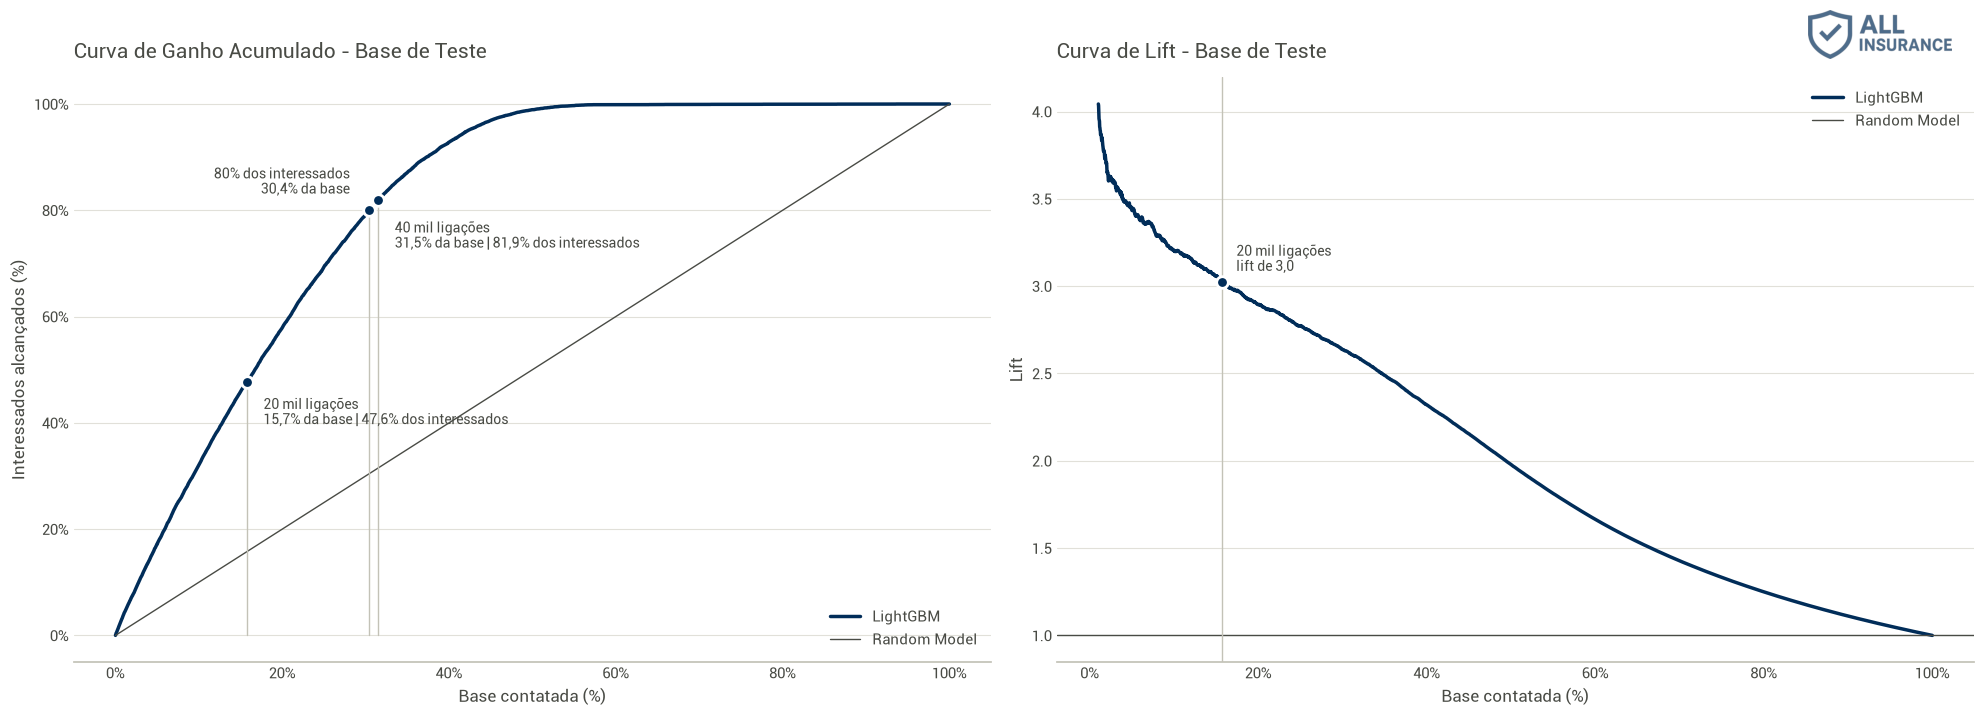

In [75]:
gain_test = cumulative_gain( y_test, yhat_lgbm_tuned )

# proporção da base necessária para alcançar 80% dos interessados
perc_80 = gain_test.loc[gain_test['perc_interessados'] >= 0.8, 'perc_base'].iloc[0]

PERC_CALLS_40K = 40000 / df_novos.shape[0]
recall_40k = recall_at_k( y_test, yhat_lgbm_tuned, int( len( y_test ) * PERC_CALLS_40K ) )

fig, axs = plt.subplots( 1, 2, figsize=(20, 7) )

aux = gain_test.iloc[::20]

# curva de ganho acumulado
axs[0].plot( aux['perc_base'], aux['perc_interessados'], color=COLOR_MAIN, linewidth=2.5, label='LightGBM' )
axs[0].plot( [0, 1], [0, 1], color=COLOR_TEXT, linewidth=1, label='Random Model' )

# pontos de interesse: texto, posição do rótulo e alinhamento
points = [
    ( PERC_CALLS, recall_20k, f'20 mil ligações\n{fmt_perc( PERC_CALLS )} da base | {fmt_perc( recall_20k )} dos interessados', ( 12, -30 ), 'left' ),
    ( PERC_CALLS_40K, recall_40k, f'40 mil ligações\n{fmt_perc( PERC_CALLS_40K )} da base | {fmt_perc( recall_40k )} dos interessados', ( 12, -34 ), 'left' ),
    ( perc_80, 0.8, f'80% dos interessados\n{fmt_perc( perc_80 )} da base', ( -14, 12 ), 'right' ) ]

for perc, recall, text, offset, ha in points:
    axs[0].plot( [perc, perc], [0, recall], color=COLOR_AXIS, linewidth=1 )
    axs[0].scatter( perc, recall, s=70, color=COLOR_MAIN, edgecolor='white', linewidth=2, zorder=4 )
    axs[0].annotate( text, xy=( perc, recall ), xytext=offset, textcoords='offset points', ha=ha, fontsize=10, color=COLOR_TEXT )

axs[0].xaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
axs[0].yaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
axs[0].legend( frameon=False, fontsize=11, loc='lower right' )
set_chart( axs[0], 'Curva de Ganho Acumulado - Base de Teste', 'Base contatada (%)', 'Interessados alcançados (%)' )

# curva de lift
aux = aux[aux['perc_base'] >= 0.01]
axs[1].plot( aux['perc_base'], aux['lift'], color=COLOR_MAIN, linewidth=2.5, label='LightGBM' )
axs[1].axhline( 1, color=COLOR_TEXT, linewidth=1, label='Random Model' )
axs[1].axvline( PERC_CALLS, color=COLOR_AXIS, linewidth=1 )
axs[1].scatter( PERC_CALLS, lift_20k, s=70, color=COLOR_MAIN, edgecolor='white', linewidth=2, zorder=4 )
axs[1].annotate( f'20 mil ligações\nlift de {fmt_dec( lift_20k )}', xy=( PERC_CALLS, lift_20k ), xytext=( 10, 8 ),
                 textcoords='offset points', fontsize=10, color=COLOR_TEXT )
axs[1].xaxis.set_major_formatter( mtick.PercentFormatter( 1.0, decimals=0 ) )
axs[1].legend( frameon=False, fontsize=11 )
set_chart( axs[1], 'Curva de Lift - Base de Teste', 'Base contatada (%)', 'Lift' )

fig.tight_layout()
add_logo( fig )
save_fig( fig, 'curva_ganho_lift' )

## 9.3. E se a capacidade do time de vendas aumentar para 40.000 ligações?

In [76]:
print( f'Fazendo 40.000 ligações ({fmt_perc( PERC_CALLS_40K )} da base), o time de vendas contata {fmt_perc( recall_40k )} dos clientes interessados.' )
print( f'Isso representa cerca de {fmt_int( recall_40k * interested_novos )} clientes interessados, contra {fmt_int( PERC_CALLS_40K * interested_novos )} ligando sem nenhum critério.' )

Fazendo 40.000 ligações (31,5% da base), o time de vendas contata 81,9% dos clientes interessados.
Isso representa cerca de 12.745 clientes interessados, contra 4.903 ligando sem nenhum critério.


## 9.4. Quantas ligações o time de vendas precisa fazer para contatar 80% dos clientes interessados?

In [77]:
calls_80 = int( np.ceil( perc_80 * df_novos.shape[0] ) )

print( f'Para contatar 80% dos clientes interessados, o time de vendas precisa ligar para {fmt_perc( perc_80 )} da base: {fmt_int( calls_80 )} ligações.' )
print( f'Sem o modelo, seriam necessárias {fmt_int( 0.8 * df_novos.shape[0] )} ligações (80% da base).' )

Para contatar 80% dos clientes interessados, o time de vendas precisa ligar para 30,4% da base: 38.662 ligações.
Sem o modelo, seriam necessárias 101.630 ligações (80% da base).


## 9.5. Resultado para o Negócio

In [78]:
tab = [['Cenário', 'Ligações', 'Interessados alcançados (modelo)', 'Interessados alcançados (aleatório)', 'Ganho']]

for name, calls, recall in [( 'Capacidade atual', CALLS, recall_20k ), ( 'Capacidade dobrada', 40000, recall_40k ), ( '80% dos interessados', calls_80, 0.8 )]:
    perc = calls / df_novos.shape[0]
    tab.append( [name, fmt_int( calls ),
                 f'{fmt_int( recall * interested_novos )} ({fmt_perc( recall )})',
                 f'{fmt_int( perc * interested_novos )} ({fmt_perc( perc )})',
                 f'{fmt_dec( recall / perc )}x'] )

print( tabulate( tab, headers='firstrow', disable_numparse=True ) )

Cenário               Ligações    Interessados alcançados (modelo)    Interessados alcançados (aleatório)    Ganho
--------------------  ----------  ----------------------------------  -------------------------------------  -------
Capacidade atual      20.000      7.412 (47,6%)                       2.451 (15,7%)                          3,0x
Capacidade dobrada    40.000      12.745 (81,9%)                      4.903 (31,5%)                          2,6x
80% dos interessados  38.662      12.456 (80,0%)                      4.739 (30,4%)                          2,6x


In [79]:
# ligações que seriam necessárias, sem o modelo, para alcançar os mesmos interessados das 20.000 ligações
calls_random_equivalent = recall_20k * df_novos.shape[0]

print( f'Para alcançar os mesmos {fmt_int( recall_20k * interested_novos )} interessados sem o modelo, seriam necessárias {fmt_int( calls_random_equivalent )} ligações.' )
print( f'Ou seja, o modelo economiza {fmt_int( calls_random_equivalent - CALLS )} ligações ({fmt_perc( 1 - CALLS / calls_random_equivalent )} a menos).' )

Para alcançar os mesmos 7.412 interessados sem o modelo, seriam necessárias 60.472 ligações.
Ou seja, o modelo economiza 40.472 ligações (66,9% a menos).


**Com o modelo, o time de vendas alcança 3 vezes mais clientes interessados com as mesmas 20.000 ligações. Sem o modelo, seriam necessárias mais de 60 mil ligações para alcançar o mesmo resultado.**

# 10.0. DEPLOY DO MODELO PARA PRODUÇÃO

A API recebe os dados dos clientes no mesmo formato do banco de dados, aplica as mesmas transformações do notebook com os scalers e encoders salvos na pasta `api/parameter` e devolve os dados originais acrescidos do `score` de propensão de compra.

## 10.1. Classe AllInsurance

In [80]:
%%writefile ../api/allinsurance/AllInsurance.py
import os
import pickle
import pandas as pd


class AllInsurance( object ):
    def __init__( self ):
        # caminho da pasta da API, a partir da localização deste arquivo
        self.home_path = os.path.dirname( os.path.dirname( os.path.abspath( __file__ ) ) )

        # scalers e encoders treinados no notebook
        self.annual_premium_scaler        = pickle.load( open( os.path.join( self.home_path, 'parameter', 'annual_premium_scaler.pkl' ), 'rb' ) )
        self.age_scaler                   = pickle.load( open( os.path.join( self.home_path, 'parameter', 'age_scaler.pkl' ), 'rb' ) )
        self.region_code_encoder          = pickle.load( open( os.path.join( self.home_path, 'parameter', 'region_code_encoder.pkl' ), 'rb' ) )
        self.policy_sales_channel_encoder = pickle.load( open( os.path.join( self.home_path, 'parameter', 'policy_sales_channel_encoder.pkl' ), 'rb' ) )

        # colunas que a API precisa receber
        self.cols_required = ['gender', 'age', 'region_code', 'driving_license', 'previously_insured',
                              'annual_premium', 'policy_sales_channel', 'vehicle_age', 'vehicle_damage']

        # features do modelo, na mesma ordem utilizada no treinamento
        self.cols_selected = ['age', 'gender', 'driving_license', 'region_code', 'previously_insured',
                              'annual_premium', 'policy_sales_channel', 'vehicle_age', 'vehicle_damage']

    def data_cleaning( self, df1 ):

        # ALTERAÇÃO DE TIPOS
        cols_int = ['age', 'region_code', 'driving_license', 'previously_insured', 'policy_sales_channel']
        for col in cols_int:
            df1[col] = pd.to_numeric( df1[col] ).astype( 'int64' )

        df1['annual_premium'] = pd.to_numeric( df1['annual_premium'] ).astype( 'float64' )
        if df1['annual_premium'].isna().any():
            raise ValueError( 'annual_premium possui valores vazios' )

        # PADRONIZAÇÃO DAS CATEGORIAS: ignora espaços extras e maiúsculas/minúsculas
        for col in ['gender', 'vehicle_age', 'vehicle_damage']:
            df1[col] = df1[col].astype( str ).str.strip().str.lower()

        return df1

    def feature_engineering( self, df2 ):

        # vehicle_age
        vehicle_age_map = { '< 1 year': 'menos_de_1_ano', '1-2 year': 'entre_1_e_2_anos', '> 2 years': 'mais_de_2_anos' }
        df2['vehicle_age'] = df2['vehicle_age'].map( vehicle_age_map )

        # vehicle_damage
        vehicle_damage_map = { 'yes': 1, 'no': 0 }
        df2['vehicle_damage'] = df2['vehicle_damage'].map( vehicle_damage_map )

        # gender
        gender_map = { 'male': 'masculino', 'female': 'feminino' }
        df2['gender'] = df2['gender'].map( gender_map )

        # VALIDAÇÃO: uma categoria desconhecida vira um valor vazio e geraria um score errado
        cols_invalid = [col for col in ['gender', 'vehicle_age', 'vehicle_damage'] if df2[col].isna().any()]
        if cols_invalid:
            raise ValueError( f'categorias desconhecidas nas colunas {cols_invalid}' )

        return df2

    def data_preparation( self, df5 ):

        # RESCALING

        # annual_premium - Robust Scaler
        df5['annual_premium'] = self.annual_premium_scaler.transform( df5[['annual_premium']].values )

        # age - Min-Max Scaler
        df5['age'] = self.age_scaler.transform( df5[['age']].values )

        # ENCODING

        # gender - Binary Encoding
        df5['gender'] = df5['gender'].map( { 'feminino': 0, 'masculino': 1 } )

        # vehicle_age - Ordinal Encoding
        df5['vehicle_age'] = df5['vehicle_age'].map( { 'menos_de_1_ano': 0, 'entre_1_e_2_anos': 1, 'mais_de_2_anos': 2 } )

        # region_code - Target Encoding
        df5['region_code'] = self.region_code_encoder.transform( df5[['region_code']] )

        # policy_sales_channel - Target Encoding
        df5['policy_sales_channel'] = self.policy_sales_channel_encoder.transform( df5[['policy_sales_channel']] )

        return df5[self.cols_selected]

    def get_prediction( self, model, original_data, test_data ):
        # predição: probabilidade de o cliente ter interesse no seguro automotivo
        pred = model.predict_proba( test_data )[:, 1]

        # junta o score aos dados originais
        original_data['score'] = pred

        return original_data.to_json( orient='records' )

Overwriting ../api/allinsurance/AllInsurance.py


## 10.2. API Handler

In [81]:
%%writefile ../api/handler.py
import os
import json
import pickle
import pandas as pd

from flask                     import Flask, request, Response
from allinsurance.AllInsurance import AllInsurance

# caminho da pasta da API
home_path = os.path.dirname( os.path.abspath( __file__ ) )

# carregando o modelo
model = pickle.load( open( os.path.join( home_path, 'model', 'model_lgbm.pkl' ), 'rb' ) )

# instância da classe AllInsurance: os scalers e encoders são carregados uma única vez
pipeline = AllInsurance()

# inicializa a API
app = Flask( __name__ )

@app.route( '/', methods=['GET'] )
def index():
    return Response( json.dumps( { 'status': 'online' } ), status=200, mimetype='application/json' )

@app.route( '/allinsurance/predict', methods=['POST'] )
def allinsurance_predict():
    test_json = request.get_json( silent=True )

    if test_json: # há dados
        if isinstance( test_json, dict ): # um único cliente
            test_raw = pd.DataFrame( test_json, index=[0] )
        elif isinstance( test_json, list ) and all( isinstance( x, dict ) for x in test_json ): # vários clientes
            test_raw = pd.DataFrame( test_json, columns=test_json[0].keys() )
        else:
            return Response( json.dumps( { 'erro': 'Envie um cliente ou uma lista de clientes no formato JSON' }, ensure_ascii=False ), status=400, mimetype='application/json' )

        # verifica se todas as colunas necessárias foram enviadas
        cols_missing = [col for col in pipeline.cols_required if col not in test_raw.columns]
        if cols_missing:
            return Response( json.dumps( { 'erro': f'Colunas ausentes: {cols_missing}' }, ensure_ascii=False ), status=400, mimetype='application/json' )

        try:
            # limpeza dos dados
            df1 = pipeline.data_cleaning( test_raw.copy() )

            # feature engineering
            df2 = pipeline.feature_engineering( df1 )

            # preparação dos dados
            df3 = pipeline.data_preparation( df2 )

        except ( ValueError, TypeError ) as e:
            return Response( json.dumps( { 'erro': f'Dados inválidos: {e}' }, ensure_ascii=False ), status=400, mimetype='application/json' )

        # predição
        df_response = pipeline.get_prediction( model, test_raw, df3 )

        return Response( df_response, status=200, mimetype='application/json' )

    else:
        return Response( '{}', status=200, mimetype='application/json' )

if __name__ == '__main__':
    port = int( os.environ.get( 'PORT', 5000 ) )
    app.run( host='0.0.0.0', port=port )

Overwriting ../api/handler.py


## 10.3. API Tester

Para testar a API localmente, ela é iniciada em segundo plano. Em seguida, uma amostra de novos clientes é enviada e os scores retornados são comparados com os scores calculados no notebook.

In [82]:
# inicia a API localmente em segundo plano, na porta 5001
api_process = subprocess.Popen( [sys.executable, 'handler.py'], cwd='../api', env={ **os.environ, 'PORT': '5001' },
                                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL )

url = 'http://127.0.0.1:5001'

# aguarda a API ficar disponível
for _ in range( 30 ):
    try:
        if requests.get( url ).status_code == 200:
            print( 'API online' )
            break
    except requests.exceptions.ConnectionError:
        pass
    time.sleep( 1 )
else:
    api_process.terminate()
    raise RuntimeError( 'A API não iniciou' )

API online


In [83]:
# amostra de novos clientes, no mesmo formato do banco de dados
df_test_api = df_novos.sample( 10, random_state=42 )

# converte o dataframe para json
data = json.dumps( df_test_api.to_dict( orient='records' ) )

# chamada da API
header = { 'Content-type': 'application/json' }
r = requests.post( url + '/allinsurance/predict', data=data, headers=header )
print( f'Status Code {r.status_code}' )

d1 = pd.DataFrame( r.json() ).sort_values( 'score', ascending=False )
d1

Status Code 200


,id_cliente,gender,age,region_code,driving_license,id_apolice,previously_insured,annual_premium,policy_sales_channel,vintage,id_veiculo,vehicle_age,vehicle_damage,score
0,491724,Female,36,29.0,1,491724,0,2630.0,156.0,56,491724,1-2 Year,Yes,0.324331
1,468163,Female,43,21.0,1,468163,0,32003.0,124.0,162,468163,1-2 Year,Yes,0.281205
7,441421,Male,52,20.0,1,441421,0,2630.0,26.0,264,441421,> 2 Years,Yes,0.240963
5,479879,Female,22,8.0,1,479879,0,61626.0,124.0,120,479879,1-2 Year,Yes,0.176244
9,476400,Male,60,8.0,1,476400,1,2630.0,26.0,164,476400,1-2 Year,Yes,0.004161
8,382073,Male,25,11.0,1,382073,1,32819.0,152.0,298,382073,< 1 Year,No,0.001377
2,419450,Male,22,28.0,1,419450,1,31631.0,160.0,128,419450,< 1 Year,No,0.000939
4,385006,Male,33,41.0,1,385006,1,38284.0,152.0,256,385006,< 1 Year,No,0.000921
6,394956,Female,28,30.0,1,394956,1,25345.0,152.0,244,394956,< 1 Year,No,0.000842
3,384310,Male,25,50.0,1,384310,1,31831.0,152.0,262,384310,< 1 Year,No,0.000812


In [84]:
# compara os scores da API com os scores calculados no notebook
aux = pd.merge( d1[['id_cliente', 'score']], df_ranking[['id_cliente', 'score']], how='inner', on='id_cliente', suffixes=( '_api', '_notebook' ) )

print( f"Maior diferença entre os scores da API e do notebook: {( aux['score_api'] - aux['score_notebook'] ).abs().max():.2e}" )

Maior diferença entre os scores da API e do notebook: 4.91e-11


In [85]:
# encerra a API local
api_process.terminate()

## 10.4. Base de Novos Clientes para o Google Sheets

Amostra de novos clientes para a demonstração da planilha no Google Sheets, que chama a API publicada e ordena os clientes pelo score.

In [86]:
cols_sheets = ['id_cliente', 'gender', 'age', 'region_code', 'driving_license', 'previously_insured',
               'annual_premium', 'policy_sales_channel', 'vintage', 'vehicle_age', 'vehicle_damage']

df_sheets = df_novos[cols_sheets].sample( 1000, random_state=42 )
df_sheets['region_code'] = df_sheets['region_code'].astype( 'int64' )
df_sheets['policy_sales_channel'] = df_sheets['policy_sales_channel'].astype( 'int64' )

df_sheets.to_csv( '../google-sheets/novos_clientes_amostra.csv', index=False )
df_sheets.head()

,id_cliente,gender,age,region_code,driving_license,previously_insured,annual_premium,policy_sales_channel,vintage,vehicle_age,vehicle_damage
491723,491724,Female,36,29,1,0,2630.0,156,56,1-2 Year,Yes
468162,468163,Female,43,21,1,0,32003.0,124,162,1-2 Year,Yes
419449,419450,Male,22,28,1,1,31631.0,160,128,< 1 Year,No
384309,384310,Male,25,50,1,1,31831.0,152,262,< 1 Year,No
385005,385006,Male,33,41,1,1,38284.0,152,256,< 1 Year,No
